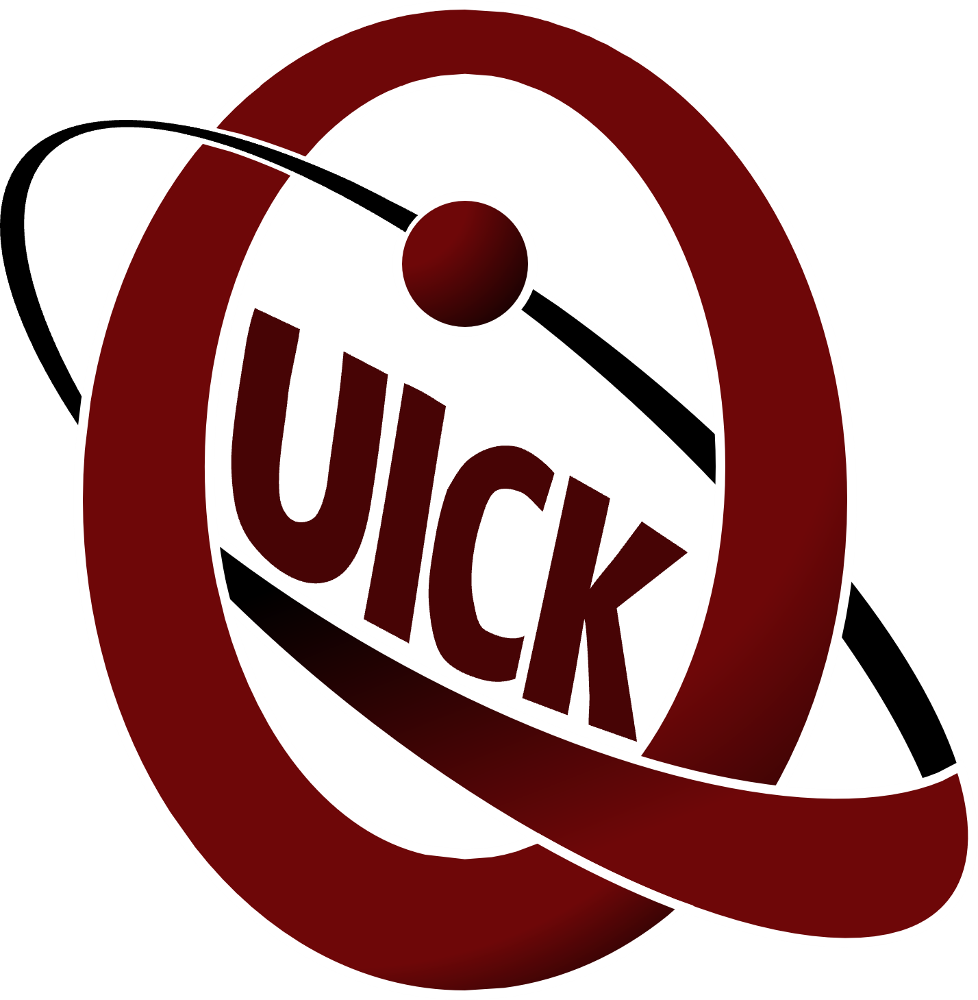

# Q-LINK — Connect the Three Laboratories

**2026 Qiskit Fall Fest · QUICK · Korea University | Participant Edition v4**

Alice, Bob, and Charlie are preparing to bring a quantum network into operation across their three laboratories. As the engineer responsible for the network, you will inspect the measurement equipment and entanglement resources, then repair a circuit that transfers Alice's quantum state to Bob. Finally, you will test whether the three laboratories can coordinate their responses without communicating after receiving their inputs.

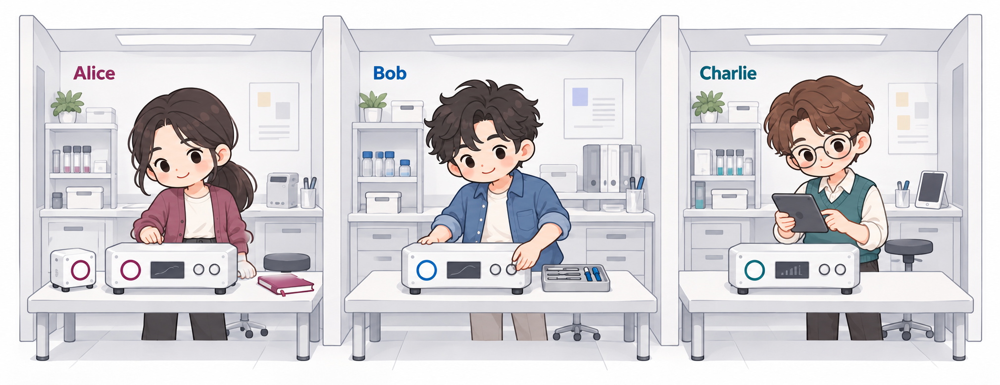

| Commissioning test | Task | Points |
|---|---|---:|
| 1. Measurement and Entanglement | Distinguish states using measurement statistics and prepare shared resources | 30 |
| 2. Quantum Teleportation | Diagnose a faulty teleportation circuit and restore the input state and its entanglement | 40 |
| 3. GHZ–Mermin Game | Compare the performance of classical and quantum strategies in a cooperative task | 30 |
| Optional Extensions | Transfer a two-qubit state and analyze phase errors | 20 additional |

[Getting Started](#start) · [1. Measurement and Entanglement](#part1) · [2. Teleportation](#part2) · [3. GHZ–Mermin Game](#part3) · [Optional Extensions](#optional) · [Network Commissioning Report and Submission](#finish)


<a id="start"></a>

# Getting Started

This notebook contains everything needed to solve the exercises, run the automatic grader, and generate a submission ZIP in **Colab, VS Code, or Jupyter**. All figures are embedded in the notebook. An internet connection is required for the initial package installation.

| Environment | Requirements |
|---|---|
| Colab | Use a Python CPU runtime. |
| VS Code or Jupyter | Select a Python 3.10–3.13 kernel. Python 3.12 is recommended for local use. |

If you opened the GitHub notebook in Colab, save your own copy before beginning.

1. **Run only the Setup A cell first.** It installs the [official grader release v2.0.5](https://github.com/equivoque-jk/qff-2026-grader/releases/tag/v2.0.5) and the tools used in the experiments. Packages are not reinstalled if the required versions are already available. This edition automatically uses English grading feedback and submission instructions.
2. **Only if prompted to restart**, select **Runtime → Restart session** in Colab, or restart the kernel in VS Code or Jupyter. Then run Setup A again.
3. Once the setup completion message appears, run **Setup B, C, and D**, then work through the provided tools and exercise cells in each part from top to bottom.
4. After completing your work, select **Run All** to generate the grading results and submission ZIP in the final cell. **Also save the `.ipynb` containing your solutions** and submit it together with the ZIP.

If installation fails, check the error message in Setup A and your internet connection. After restarting the session or kernel, rerun the required cells even if previous outputs are still visible.

**Follow the event announcements** for the submission destination, deadline, individual or team submission requirements, and contact channel. See [Network Commissioning Report and Submission](#finish) for detailed instructions on saving your files.


In [ ]:
#@title Setup A — Prepare the Grader and Experiment Environment (Automatic)
# Install the specified GitHub release. Do not reinstall packages if the environment is already ready.
import importlib as _qff_importlib
import importlib.metadata as _qff_metadata
import subprocess as _qff_subprocess
import sys as _qff_sys

print("[Setup A 1/4] Checking Python and installed packages.", flush=True)
if not ((3, 10) <= _qff_sys.version_info[:2] < (3, 14)):
    raise RuntimeError("A Python 3.10–3.13 kernel is required. Select a Colab Python runtime or a local kernel with a supported version.")
try:
    from google.colab import files as _qff_colab_files
except ImportError:
    _qff_is_colab = False
else:
    _qff_is_colab = True

_qff_required = {
    "qff-local-grader": "2.0.5", "qiskit": "2.3.1", "numpy": "2.2.6",
    "psutil": "7.2.2", "qiskit-aer": "0.17.2", "matplotlib": "3.10.8",
    "pylatexenc": "2.10", "ipython": None, "nbformat": None,
}
_qff_colab_ipython = None
if _qff_is_colab:
    # Colab's shell depends on its own IPython version. Preserve the live kernel version.
    _qff_colab_ipython = getattr(_qff_sys.modules.get("IPython"), "__version__", None)
    if _qff_colab_ipython is None:
        _qff_colab_ipython = _qff_metadata.version("ipython")
    _qff_required["ipython"] = _qff_colab_ipython
    print("Preserving IPython " + _qff_colab_ipython + " for the Colab kernel.", flush=True)

_qff_install_needed = False
_qff_before_versions = {}
for _qff_distribution, _qff_expected in _qff_required.items():
    try:
        _qff_actual = _qff_metadata.version(_qff_distribution)
    except _qff_metadata.PackageNotFoundError:
        _qff_before_versions[_qff_distribution] = None
        _qff_install_needed = True
    else:
        _qff_before_versions[_qff_distribution] = _qff_actual
        if _qff_expected is not None and _qff_actual != _qff_expected:
            _qff_install_needed = True

if _qff_install_needed:
    print("[Setup A 2/4] Checking packages to install from GitHub release v2.0.5.", flush=True)
    _qff_package_url = "https://github.com/equivoque-jk/qff-2026-grader/releases/download/v2.0.5/qff_local_grader-2.0.5-py3-none-any.whl#sha256=c21b9905cddbcf33f7281bbb1d1870454058f5afb68f029d5fbe14e7069374f7"
    _qff_modules = {
        "qff-local-grader": "qff_grader", "qiskit": "qiskit", "numpy": "numpy",
        "psutil": "psutil", "qiskit-aer": "qiskit_aer", "matplotlib": "matplotlib",
        "pylatexenc": "pylatexenc", "ipython": "IPython", "nbformat": "nbformat",
    }
    _qff_loaded_before_install = {
        _qff_dist: getattr(_qff_sys.modules[_qff_module], "__version__", None)
        for _qff_dist, _qff_module in _qff_modules.items() if _qff_module in _qff_sys.modules
    }
    _qff_install_command = [
        _qff_sys.executable, "-m", "pip", "install", "--progress-bar", "off",
        "qff-local-grader[notebook] @ " + _qff_package_url,
    ]
    if _qff_colab_ipython:
        _qff_install_command.append("ipython==" + _qff_colab_ipython)
    print("[Setup A 3/4] Installing packages. The log below shows progress. (Up to 10 minutes)", flush=True)
    import queue as _qff_queue
    import threading as _qff_threading
    import time as _qff_time
    _qff_process = _qff_subprocess.Popen(
        _qff_install_command, stdout=_qff_subprocess.PIPE, stderr=_qff_subprocess.STDOUT,
        text=True, bufsize=1,
    )
    _qff_lines = _qff_queue.Queue()
    def _qff_read_install_log():
        try:
            for _qff_line in _qff_process.stdout:
                _qff_lines.put(_qff_line)
        finally:
            _qff_lines.put(None)
    _qff_reader = _qff_threading.Thread(target=_qff_read_install_log, daemon=True)
    _qff_reader.start()
    _qff_deadline = _qff_time.monotonic() + 600
    _qff_last_notice = _qff_time.monotonic()
    while True:
        if _qff_time.monotonic() >= _qff_deadline:
            _qff_process.kill()
            _qff_process.wait(timeout=10)
            raise RuntimeError("Installation was stopped after exceeding the 10-minute limit. Check your network connection, then run Setup A again.")
        try:
            _qff_line = _qff_lines.get(timeout=1)
        except _qff_queue.Empty:
            if _qff_time.monotonic() - _qff_last_notice >= 30:
                print("Installation is still running. Waiting for the next log entry.", flush=True)
                _qff_last_notice = _qff_time.monotonic()
            continue
        if _qff_line is None:
            break
        print(_qff_line, end="", flush=True)
    try:
        _qff_returncode = _qff_process.wait(timeout=max(1, _qff_deadline - _qff_time.monotonic()))
    except _qff_subprocess.TimeoutExpired:
        _qff_process.kill()
        _qff_process.wait(timeout=10)
        raise RuntimeError("Installation exceeded the 10-minute limit. Check the installation log in Setup A.") from None
    if _qff_returncode != 0:
        raise RuntimeError("Installation did not complete. Check the pip error above, then run Setup A again.")
    print("Package installation is complete.", flush=True)
    _qff_importlib.invalidate_caches()
    _qff_changed_loaded = [
        _qff_dist for _qff_dist, _qff_loaded_version in _qff_loaded_before_install.items()
        if _qff_before_versions[_qff_dist] != _qff_metadata.version(_qff_dist)
        and _qff_loaded_version != _qff_metadata.version(_qff_dist)
    ]
    if _qff_changed_loaded:
        print("Installation succeeded. Earlier versions remain loaded in memory: " + ", ".join(_qff_changed_loaded), flush=True)
        raise RuntimeError(
            "Runtime issue: in Colab, select 'Runtime → Restart session', then "
            "run only Setup A again. In VS Code or Jupyter, restart the kernel, then run Setup A. "
            "Once setup is complete, run Setup B, C, and D and the required exercise cells in order. "
            "Select 'Run All' when you are ready to grade all answers and create the submission ZIP."
        )
else:
    print("[Setup A 2–3/4] The required versions are installed. Skipping installation.", flush=True)

print("[Setup A 4/4] Checking the loaded versions and experiment environment.", flush=True)
import qff_grader as _qff_package
if _qff_package.__version__ != "2.0.5":
    raise RuntimeError("An earlier grader version remains loaded in memory. In Colab, select 'Runtime → Restart session'; in VS Code or Jupyter, restart the kernel. Then run Setup A again.")
from qff_grader import check_runtime, reset_submission_state, finalize_submission
_qff_runtime = check_runtime(require_notebook=True, language="en")
reset_submission_state(globals())
print("QFF 2.0.5 is ready — run Setup B, C, and D and the required exercise cells in order, completing the TODOs.", flush=True)
print("To grade all answers and create the submission ZIP, select 'Runtime → Run all' in Colab or 'Run All' in VS Code or Jupyter.", flush=True)


In [ ]:
#@title Setup B — Check Installed Versions
import sys, qiskit, qiskit_aer, numpy, matplotlib
print("Python", sys.version.split()[0])
print("Qiskit", qiskit.__version__, "Aer", qiskit_aer.__version__)
print("NumPy", numpy.__version__, "Matplotlib", matplotlib.__version__)
assert qiskit.__version__ == "2.3.1" and qiskit_aer.__version__ == "0.17.2"

In [ ]:
#@title Setup C — Shared Execution Tools
"""Provided helpers, embedded into each notebook so Colab needs no local files."""
import itertools
import numpy as np
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.circuit import Clbit
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace, state_fidelity
from qiskit_aer import AerSimulator
from IPython.display import display

SHOTS = 4096
SEED = 20260909
BACKEND = AerSimulator(max_parallel_threads=2)


def compile_for_aer(qc, seed=SEED):
    # Lower state preparation to portable gates, avoiding backend-specific
    # multiplexer instructions. This also works inside classical if blocks.
    return transpile(qc, basis_gates=["u", "cx"], optimization_level=0,
                     seed_transpiler=seed, num_processes=1)

"""Circuit contract for educational checks; not a Python security sandbox."""
from qiskit.circuit import Barrier, Clbit, IfElseOp
from qiskit.circuit.library import HGate, XGate, ZGate, CXGate, SGate, SdgGate


def validate_fragment(qc, nq, nc=0, allowed=("h", "x", "z", "cx"), conditional=False):
    """Check standard gate identity and arity, including conditional bodies."""
    if not isinstance(qc, QuantumCircuit) or (qc.num_qubits, qc.num_clbits) != (nq, nc):
        raise ValueError(f"Expected QuantumCircuit({nq}, {nc})")
    if qc.parameters:
        raise ValueError("Bind all circuit parameters before submission")
    standard = {"h": HGate, "x": XGate, "z": ZGate, "cx": CXGate,
                "s": SGate, "sdg": SdgGate}
    for item in qc.data:
        op = item.operation
        if type(op) is Barrier:
            continue
        if type(op) is IfElseOp and conditional:
            condition = op.condition
            if not isinstance(condition, tuple) or len(condition) != 2:
                raise ValueError("Use a single local classical bit in if_test")
            bit, value = condition
            if not isinstance(bit, Clbit) or value not in (0, 1) or bit not in qc.clbits:
                raise ValueError("Use a single local classical bit in if_test")
            for block in op.blocks:
                validate_fragment(block, block.num_qubits, block.num_clbits, allowed, True)
            continue
        gate_class = standard.get(op.name)
        if op.name not in allowed or gate_class is None:
            raise ValueError(f"Operation not allowed here: {op.name}")
        canonical = gate_class()
        if (type(op) not in (gate_class, type(canonical)) or
                op.num_qubits != canonical.num_qubits or op.num_clbits or op.params or
                (op.name == "cx" and op.ctrl_state != canonical.ctrl_state)):
            raise ValueError(f"Use the standard Qiskit gate for {op.name}")
    return qc


def bit_at(key, index):
    """Global classical-bit index; independent of printed register separators."""
    return int(key.replace(" ", "")[-1-index])

_qff_experiment_errors = []


def _qff_record_experiment_error(label, exc):
    _qff_experiment_errors.append({"experiment": label, "type": type(exc).__name__, "message": str(exc)})
    print(f"Experiment check — {label}: {type(exc).__name__}: {exc}")
    print("Skipping the output for this experiment. Check the results for each exercise in the final automatic grading cell.")


def run_if_ready(action):
    """Keep ordinary unfinished/incorrect experiment output from blocking grading."""
    try:
        return action()
    except NotImplementedError as exc:
        print(f"Incomplete — implement the corresponding TODO, then run this cell again: {exc}")
    except Exception as exc:
        _qff_record_experiment_error(getattr(action, "__name__", "experiment"), exc)


from contextlib import contextmanager as _qff_contextmanager


@_qff_contextmanager
def _qff_experiment(label):
    """Preserve module-level experiment variables while reporting ordinary errors."""
    try:
        yield
    except NotImplementedError as exc:
        print(f"Incomplete — implement the corresponding TODO, then run this cell again: {exc}")
    except Exception as exc:
        _qff_record_experiment_error(label, exc)

def show_game(report):
    print("input       correlator    win rate")
    for row in report["rows"]:
        xyz = "".join(map(str, row["input"]))
        print(f"{xyz:>5s}       {row['correlator']: .6f}    {row['win_rate']:.6f}")
    print(f"average win={report['p_win']:.6f}, M={report['M']:.6f}")

def show_fidelity(report):
    print(f"F_hat={report['fidelity']:.6f}")
    print("Alice bits     shots    branch F_hat")
    for bits, row in report["branches"].items():
        print(f"{bits:>10s}     {row['shots']:5d}    {row['fidelity']:.6f}")


In [ ]:
#@title Setup D — Measurement and Plotting Tools
"""Provided measurement helpers for the integrated QFF notebook."""
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp

COLORS = {"A": "#4169A1", "B": "#B77933", "reference": "#333B45"}
plt.rcParams.update({"figure.figsize": (9, 3.6), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "semibold", "figure.dpi": 120})


def initial_one_qubit(label):
    qc = QuantumCircuit(1)
    if label == "1":
        qc.x(0)
    elif label == "+":
        qc.h(0)
    elif label == "-":
        qc.x(0)
        qc.h(0)
    elif label != "0":
        raise ValueError("Use one of: 0, 1, +, -")
    return qc


def measure_subset(preparation, qubits, readout=None, shots=SHOTS, seed=SEED):
    """Each call prepares a fresh state, changes basis, then measures only listed qubits."""
    if preparation.num_clbits or shots < 1 or len(set(qubits)) != len(qubits):
        raise ValueError("Use an unmeasured preparation and distinct measured qubits")
    qc = preparation.copy()
    if readout is not None:
        validate_fragment(readout, len(qubits), allowed=("h", "x", "z", "s", "sdg"))
        qc.compose(readout, list(qubits), inplace=True)
    bits = ClassicalRegister(len(qubits), "readout")
    qc.add_register(bits)
    qc.measure(list(qubits), bits)
    counts = BACKEND.run(compile_for_aer(qc, seed), shots=shots,
                         seed_simulator=seed).result().get_counts()
    return counts


def expectation_from_counts(counts):
    total = sum(counts.values())
    if total <= 0:
        raise ValueError("Counts must contain at least one shot")
    return sum((-1)**key.replace(" ", "").count("1") * n for key, n in counts.items()) / total


def inspect_one(builder):
    qc = validate_fragment(builder(), 1)
    counts = measure_subset(qc, [0])
    display(qc.draw("mpl"))
    print("counts:", counts)
    print(f"<Z> estimate = {expectation_from_counts(counts):+.6f}")
    return counts


def inspect_four_states(builder, readout=None, draw=False):
    rows = []
    for i, label in enumerate(("0", "1", "+", "-")):
        qc = validate_fragment(builder(label), 1)
        counts = measure_subset(qc, [0], readout, seed=SEED+i)
        ev = expectation_from_counts(counts)
        rows.append((label, ev))
        if draw:
            print("Initial state:", label)
            display(qc.draw("mpl"))
    print("initial      expectation estimate")
    for label, ev in rows:
        print(f"{label:>7s}      {ev:+.6f}")
    return rows


BELL_TARGETS = {
    "Phi+": Statevector(np.array([1, 0, 0, 1])/np.sqrt(2)),
    "Phi-": Statevector(np.array([1, 0, 0, -1])/np.sqrt(2)),
    "Psi+": Statevector(np.array([0, 1, 1, 0])/np.sqrt(2)),
    "Psi-": Statevector(np.array([0, 1, -1, 0])/np.sqrt(2)),
}


def bell_experiment(transform, target):
    qc = QuantumCircuit(2)
    qc.x(0)  # Referee fixes |q1 q0> = |01>; participant cannot remove this prefix.
    qc.barrier(label="given input 01")
    qc.compose(validate_fragment(transform(target), 2), inplace=True)
    return qc


def inspect_bells(transform):
    print("target      preparation fidelity")
    for label, target in BELL_TARGETS.items():
        qc = bell_experiment(transform, label)
        print(f"{label:>6s}      {state_fidelity(Statevector(qc), target):.6f}")
        display(qc.draw("mpl"))


def plot_readout_comparison(counts_a, counts_b, title, parity=False):
    def probabilities(counts):
        n = sum(counts.values())
        if parity:
            return [sum(v for k, v in counts.items() if k.count("1") % 2 == p)/n for p in (0, 1)]
        width = len(next(iter(counts)))
        return [counts.get(f"{i:0{width}b}", 0)/n for i in range(2**width)]
    a, b = probabilities(counts_a), probabilities(counts_b)
    labels = ["even (+1)", "odd (-1)"] if parity else [f"{i:03b}" for i in range(len(a))]
    positions = np.arange(len(a))
    fig, ax = plt.subplots(figsize=(9, 3.4), layout="constrained")
    ax.bar(positions-0.18, a, width=0.36, label="Device A", color=COLORS["A"])
    ax.bar(positions+0.18, b, width=0.36, label="Device B", color=COLORS["B"], hatch="//")
    ax.set(xticks=positions, xticklabels=labels, ylim=(0, 1.08),
           ylabel="Observed fraction", xlabel="Output parity" if parity else "Measured bits (q2 q1 q0)", title=title)
    ax.legend(frameon=False, ncol=2)
    ax.text(1, 1.03, f"{sum(counts_a.values())} shots/device", transform=ax.transAxes, ha="right", fontsize=9)
    plt.show()


def inspect_sources(build_a, build_b, readout=None):
    a = validate_fragment(build_a(), 3)
    b = validate_fragment(build_b(), 4)
    counts_a = measure_subset(a, [0, 1, 2], readout, seed=SEED)
    counts_b = measure_subset(b, [0, 1, 2], readout, seed=SEED+1)
    print("Device A parity expectation:", f"{expectation_from_counts(counts_a):+.6f}")
    print("Device B parity expectation:", f"{expectation_from_counts(counts_b):+.6f}")
    plot_readout_comparison(counts_a, counts_b,
                           "Local Z readout" if readout is None else "Readout after your basis change",
                           parity=readout is not None)
    return counts_a, counts_b


def plot_game_comparison(ghz_report, coin_report):
    fig, (by_input, average) = plt.subplots(
        1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1.5, 1]}, layout="constrained")
    x = np.arange(4)
    by_input.bar(x-0.18, [r["win_rate"] for r in ghz_report["rows"]], 0.36,
                 label="GHZ", color=COLORS["A"])
    by_input.bar(x+0.18, [r["win_rate"] for r in coin_report["rows"]], 0.36,
                 label="Coin", color=COLORS["B"], hatch="//")
    by_input.set(xticks=x, xticklabels=["000", "011", "101", "110"], ylim=(0, 1.1),
                 yticks=[0, .25, .5, .75, 1], yticklabels=["0%", "25%", "50%", "75%", "100%"],
                 xlabel="Input (x y z)", ylabel="Observed win rate", title="Each input: same X/Y strategy")
    by_input.legend(frameon=False, ncol=2)
    scores = [ghz_report["p_win"], coin_report["p_win"]]
    bars = average.bar([0, 1], scores, width=.55, color=[COLORS["A"], COLORS["B"]])
    bars[1].set_hatch("//")
    average.axhline(.75, color=COLORS["reference"], linestyle="--", linewidth=1.2)
    average.text(.98, .76, "Best classical: 75%", ha="right", va="bottom", fontsize=9,
                 transform=average.get_yaxis_transform())
    average.bar_label(bars, labels=[f"{score:.1%}" for score in scores], padding=4)
    average.set(xticks=[0, 1], xticklabels=["GHZ", "Coin"], ylim=(0, 1.16),
                yticks=[0, .25, .5, .75, 1], yticklabels=["0%", "25%", "50%", "75%", "100%"],
                title="Uniform-input average")
    plt.show()


<a id="rules"></a>

## Solution and Experiment Guidelines

**Write your code only between `TODO BEGIN` and `TODO END` in the 23 answer functions.** Remove `raise NotImplementedError(...)` from that region and replace it with your implementation. Leave the function signatures, provided initialization code, final `return` statements, and all provided helper, execution, and grading cells unchanged. Leave the TODO regions unchanged for any optional exercises you choose not to complete.

| Component | What to write or check |
|---|---|
| Answer functions | Return the circuit or numerical result specified in the exercise. |
| Exercise execution cells | Inspect circuits and experimental results. Some execution cells do not call the numerical answer functions; read the instructions for each exercise. |
| Final grading cell | Checks the values returned by your answer functions and generates the submission ZIP. |
| Experiment Notes and Commissioning Report | Record observations and the calculations that support your conclusions. These sections are not automatically graded. |

**Circuit construction rules**

- Follow each exercise's requirements for circuit size and return format. Do not include measurements, `reset`, additional qubits, or postselection based on measurement outcomes in submitted circuits. The provided code adds the required measurements.
- The default allowed gates are **H/X/Z/CX**. Local measurement basis transformations use **H/X/Z**; **S/S† are additionally allowed only in `local_basis()` in Exercise 3-2**. Local operations may act only on the qubits held by the corresponding party.
- Bob's corrections use **H/X/Z and `if_test`**. Each condition must compare **a single classical bit in the returned circuit with 0 or 1**. Nest conditionals when checking multiple bits. Conditions that compare the integer value of an entire classical register or use classical logical expressions are not allowed.
- **Exercises 1-1 through 1-3 also check the gate types, counts, and order.** Do not add extra gates or modify the provided initialization, even if the final state is unchanged. `barrier` instructions used to separate circuit sections are excluded from the gate-list checks.
- Each function may use only its own arguments and the publicly stated exercise specification. States that differ only by a global phase are treated as equivalent.

**Notation and numerical results**

- State and outcome strings place the highest index on the left. For example, two-qubit states are written as $|q_1q_0\rangle$, and two-classical-bit outcomes as `c1c0`; q0 and c0 are rightmost.
- The experiments use an ideal Aer simulator. Sampling experiments use **4096 shots** per measurement setting, with the initial state prepared afresh for every shot. Counts record how many times each outcome is observed.
- Sample estimates of expectation values, winning probabilities, and fidelity are provided for observation and comparison. **Numerical answers must return values calculated from the exact probabilities or density matrices of the ideal circuit.** Matching a particular set of counts is not required.

The failure messages produced by the faulty circuits in Exercise 2-1 and optional Exercise 2-5 are experimental results intended to help you locate the defects. Analyze and correct them according to the instructions in those exercises.

<a id="part1"></a>

# 1. Measurement and Entanglement — Equipment Checks

Before testing state transfer, inspect the measurement equipment and shared resources. Begin with single-qubit measurement statistics, and investigate whether states with identical Z-basis measurement distributions can be distinguished by a different measurement. Then prepare Bell resources for two laboratories and GHZ resources for all three.

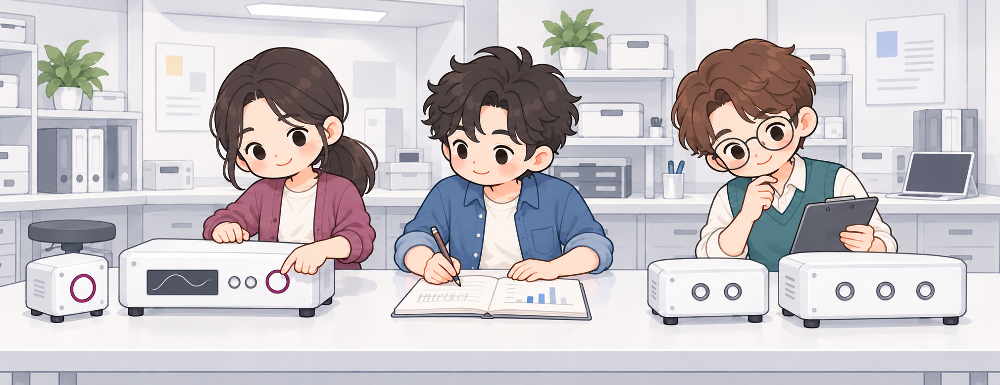


## 1-1. Reference-State Check — Z Expectation Value after an X Gate · 3 points

In `build_circuit_1_1()`, apply **exactly one X gate** to the initial state $|0\rangle$. Return a `QuantumCircuit(1)` with no measurements.

The **“Run 1-1 — Inspect the Circuit, Counts, and Z Expectation Value”** cell below adds a Z-basis measurement to a copy of your returned circuit and executes 4096 shots. It displays the counts and the estimated Z expectation value. The circuit diagram shows **only your circuit before measurement**.

**Grading criteria:** The grader checks the returned circuit's size, allowed gates, and prepared state. Excluding `barrier` instructions, the complete gate list must contain exactly one X gate; additional gates are not allowed even if they produce the same final state. The 4096-shot output above is for observation. The grader checks the state prepared by your circuit through direct calculation.

If the counts for outcomes 0 and 1 are $N_0,N_1$ and the total number of measurements is $N$, the sample estimate of the Z expectation value is $(N_0-N_1)/N$.

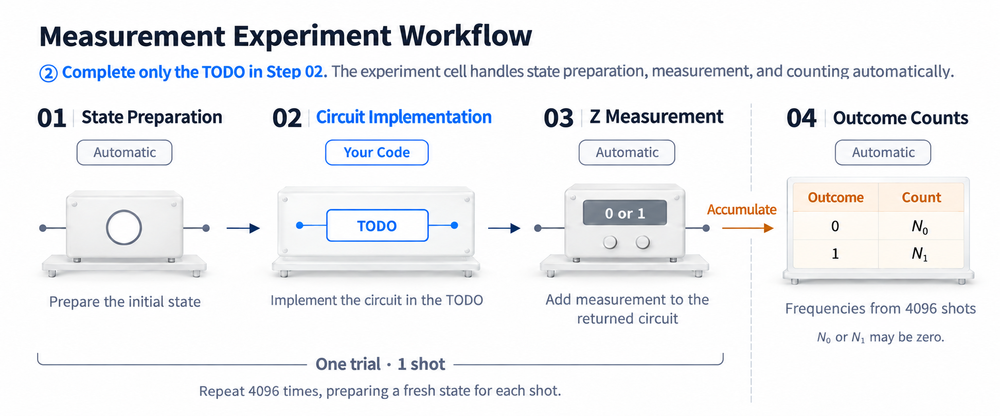

*The initial state is prepared afresh in every shot, and the provided code adds a Z measurement after your circuit.*


In [ ]:
# Exercise 1-1 — Write Code Only Between TODO BEGIN and TODO END
def build_circuit_1_1():
    "Apply one X gate to |0>. Return a 1-qubit circuit with no measurements."
    qc = QuantumCircuit(1)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("build_circuit_1_1")
    # TODO END
    return qc


In [ ]:
#@title Run 1-1 — Inspect the Circuit, Counts, and Z Expectation Value
result_1_1 = run_if_ready(lambda: inspect_one(build_circuit_1_1))

**Experiment Notes 1-1 · Ungraded**

- Which signs of the measured observable correspond to Z-basis measurement outcomes 0 and 1, respectively?
- Calculate the Z expectation value from the observed counts and compare it with the theoretical value obtained from the circuit.

Observations, calculations, and interpretation:

…


## 1-2. Reference-State Check — H and Measurement Statistics · 3 points

In `build_circuit_1_2()`, apply **exactly one H gate** to the initial state $|0\rangle$. Return a `QuantumCircuit(1)` with no measurements.

The **“Run 1-2 — Compare the H Experiment with Exercise 1-1”** cell below adds a Z-basis measurement to a copy of your returned circuit and executes 4096 shots. The circuit diagram shows only the circuit before measurement. Inspect the counts and the estimated Z expectation value.

**Grading criteria:** The grader checks the returned circuit's size, allowed gates, and prepared state. Excluding `barrier` instructions, the complete gate list must contain exactly one H gate; additional gates are not allowed even if they produce the same final state. The 4096-shot output is for observation, and matching a particular set of counts is not required.


In [ ]:
# Exercise 1-2 — Write Code Only Between TODO BEGIN and TODO END
def build_circuit_1_2():
    "Apply one H gate to |0>. Return a 1-qubit circuit with no measurements."
    qc = QuantumCircuit(1)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("build_circuit_1_2")
    # TODO END
    return qc


In [ ]:
#@title Run 1-2 — Compare the H Experiment with Exercise 1-1
result_1_2 = run_if_ready(lambda: inspect_one(build_circuit_1_2))

**Experiment Notes 1-2 · Ungraded**

- Divide the counts by the total number of shots to obtain the relative frequencies of outcomes 0 and 1, and compare them with the theoretical probabilities.
- Compare the estimated and theoretical Z expectation values, and explain how the results differ from those in Exercise 1-1.

Observations, calculations, and interpretation:

…


## 1-3. Reference-State Check — Two H Gates · 4 points

In `build_circuit_1_3(initial_state)`, apply **two H gates in succession** to the provided initial circuit. Return a `QuantumCircuit(1)` that retains the provided initialization and contains no measurements. `initial_state` is one of `"0"`, `"1"`, `"+"`, or `"-"`.

The execution cell below adds a Z-basis measurement after the two H gates to estimate the expectation value for each of the four initial states. Inspect the results for all four states.

**Grading criteria:** The grader checks the initial-state preparation and final state for all four inputs. Excluding `barrier` instructions, the complete gate list must consist of the provided initialization operations followed by two consecutive H gates. Modifying the initialization or adding other gates violates this requirement even if the final state is unchanged.


In [ ]:
# Exercise 1-3 — Write Code Only Between TODO BEGIN and TODO END
def build_circuit_1_3(initial_state):
    qc = initial_one_qubit(initial_state)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("build_circuit_1_3")
    # TODO END
    return qc


In [ ]:
#@title Run 1-3 — Compare the Four Initial States
result_1_3 = run_if_ready(lambda: inspect_four_states(build_circuit_1_3, draw=True))

**Experiment Notes 1-3 · Ungraded**

- Determine the state obtained after applying two H gates to each of the four initial states, and compare your calculations with the experimental results.
- Which distinct initial states have the same theoretical Z-basis measurement distribution?

Observations, calculations, and interpretation:

…


## 1-4. Distinguishing States through the Measurement Basis · 5 points

Design a common single-qubit transformation, `discrimination_basis()`, that distinguishes $|+\rangle$ from $|-\rangle$. Return a `QuantumCircuit(1)` with no measurements. The function receives no information about which candidate state is supplied. The provided experiment applies the same transformation to every candidate state, then measures in the Z basis.

For each of the four candidates `0`, `1`, `+`, and `-`, the execution cell below displays **the Z expectation value without a transformation** and **the Z expectation value after your transformation**. Each measurement setting uses a freshly prepared state.

**Hint:** Applying a transformation $V$ immediately before a Z measurement is equivalent to measuring $V^\dagger ZV$ on the original state. Use $HZH=X$.

**Grading criteria:** The grader checks whether the common local transformation distinguishes `+` from `-`. Equivalent implementations that reverse the signs of the measurement outcomes are also accepted.

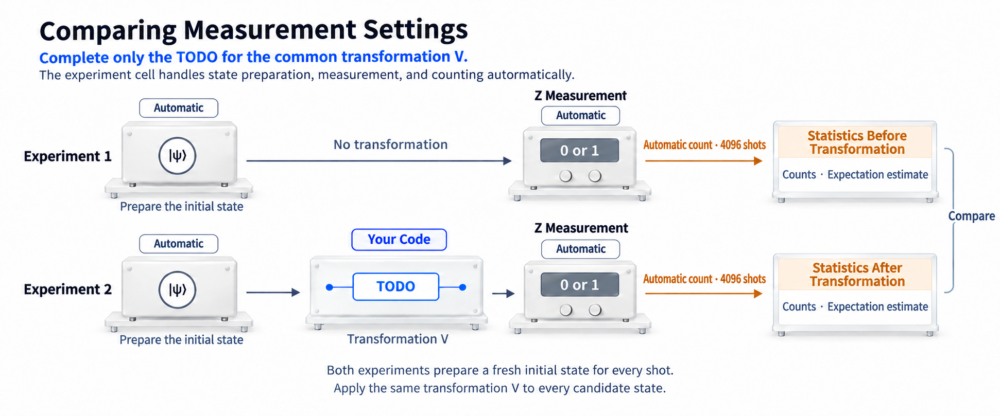

*Each measurement setting is applied to a freshly prepared state. Use the same transformation V for every candidate.*


In [ ]:
# Exercise 1-4 — Write Code Only Between TODO BEGIN and TODO END
def discrimination_basis():
    "A common 1-qubit basis transformation with no knowledge of the candidate state. No measurements."
    qc = QuantumCircuit(1)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("discrimination_basis")
    # TODO END
    return qc


In [ ]:
#@title Run 1-4 — Compare the Original and New Measurements
def inspect_discrimination():
    readout = validate_fragment(discrimination_basis(), 1, allowed=("h", "x", "z"))
    display(readout.draw("mpl"))
    print("Z readout")
    inspect_four_states(initial_one_qubit)
    print("New readout on fresh copies")
    return inspect_four_states(initial_one_qubit, readout)

result_1_4 = run_if_ready(inspect_discrimination)

**Experiment Notes 1-4 · Ungraded**

- For each of the four candidate states, compare the expectation value from a direct Z measurement with the expectation value from a Z measurement after your transformation.
- How do the conditions for distinguishing states differ between repeatedly preparing the same candidate to compare statistics from two measurement settings and receiving only one copy of an unknown state drawn from the four candidates?

Observations, calculations, and interpretation:

…


## 1-5. Preparing Teleportation Resources — The Four Bell States · 7 points

Implement `bell_transform(target)` as a transformation to append to the specified initial state $|q_1q_0\rangle=|01\rangle$. Return a `QuantumCircuit(2)` containing **only the transformation**, with no measurements. The provided code applies the initial X gate. `target` is one of `"Phi+"`, `"Phi-"`, `"Psi+"`, or `"Psi-"`.

$$|\Phi^\pm\rangle=\frac{|00\rangle\pm|11\rangle}{\sqrt2},\qquad
|\Psi^\pm\rangle=\frac{|01\rangle\pm|10\rangle}{\sqrt2}.$$

**Fidelity** measures how closely a prepared state matches a target state and takes values between 0 and 1. For a pure target state $|\phi\rangle$ and an actual state $\rho$, it is defined as $F=\langle\phi|\rho|\phi\rangle$. A fidelity of $F=1$ means that the states match. In the initial state $|q_1q_0\rangle=|01\rangle$ above, q0 is 1 and q1 is 0.

Use the **“Run 1-5 — Check the Four Bell Targets”** cell below to inspect the fidelity between the state prepared by each circuit and the corresponding target Bell state. This cell displays the circuit diagrams and fidelities.

**Grading criteria:** The grader checks whether appending your returned circuit to the specified initial state prepares each of the four target states. Global phase differences are ignored, and alternative circuit implementations that prepare the same target state are accepted.


In [ ]:
# Exercise 1-5 — Write Code Only Between TODO BEGIN and TODO END
def bell_transform(target):
    "A 2-qubit transformation circuit to append after the fixed |01> input."
    qc = QuantumCircuit(2)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("bell_transform")
    # TODO END
    return qc


In [ ]:
#@title Run 1-5 — Check the Four Bell Targets
run_if_ready(lambda: inspect_bells(bell_transform))

**Experiment Notes 1-5 · Ungraded**

- Calculate the theoretical values of ⟨ZZ⟩ and ⟨XX⟩ for each Bell state and complete the table below.
- Compare the + and − states within each of the Φ and Ψ families. How does the difference in relative phase affect the two expectation values?

| Target state | ⟨ZZ⟩ | ⟨XX⟩ |
|---|---|---|
| Phi+ | … | … |
| Phi− | … | … |
| Psi+ | … | … |
| Psi− | … | … |

Observations, calculations, and interpretation:

…


## 1-6. Inspecting Shared Resources — Two Sources with the Same Z-Basis Distribution · 8 points

Prepare and compare two shared resources to be distributed among the three laboratories.

| Source | Resource to be distributed | Function to implement and circuit to return |
|---|---|---|
| A · GHZ | $\lvert GHZ^+\rangle=(\lvert 000\rangle+\lvert 111\rangle)/\sqrt2$ | `build_ghz_state()` · `QuantumCircuit(3)` with no measurements |
| B · Coin | A mixed state obtained by preparing either 000 or 111 according to the outcome of a fair coin toss | `build_coin_flip_state()` · `QuantumCircuit(4)` with no measurements |

Both sources distribute q0, q1, and q2 to Alice, Bob, and Charlie, respectively. **For Coin, q3 is a record qubit that is inaccessible after state preparation.** The state of q0, q1, and q2 after excluding q3 must equal the Coin mixed state described above. Do not select samples based on the outcome of q3.

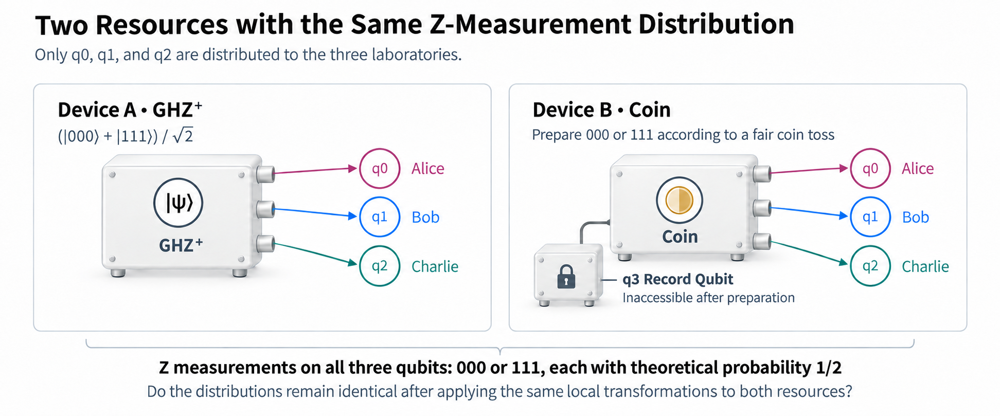

**Design a measurement setting that reveals a difference between the two resources.** `correlation_basis()` must return a `QuantumCircuit(3)` containing only H/X/Z gates and no measurements. Apply **the same transformation circuit** to GHZ and Coin; the local operations on q0, q1, and q2 may differ from one another.

1. **Preparation check:** In the first execution cell, compare the two resources' Z-basis measurement distributions without applying a transformation.
2. **Discrimination experiment:** In the next execution cell, compare the results obtained by adding Z measurements after your local transformation.

For outcomes $a,b,c$ in a single shot, define the product of signs as $(-1)^{a+b+c}$. It is +1 for an even number of 1s and −1 for an odd number. The reported **parity expectation value is the sample mean of this product**. Even when the theoretical distributions are identical, counts obtained from a finite number of shots need not match exactly.

**Hint:** To prepare Coin, you may apply H to q3, followed by CX gates from q3 to q0, q1, and q2.

**Grading criteria:** The grader checks the prepared GHZ state, the Coin mixed state after excluding q3, and whether the same local measurement reveals a difference between the two resources.


In [ ]:
# Exercise 1-6 — Write Code Only Between TODO BEGIN and TODO END
def build_ghz_state():
    "A 3-qubit GHZ+ preparation circuit with no measurements."
    qc = QuantumCircuit(3)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("build_ghz_state")
    # TODO END
    return qc


In [ ]:
# Exercise 1-6 — Write Code Only Between TODO BEGIN and TODO END
def build_coin_flip_state():
    "A 4-qubit preparation circuit that yields the Coin source when q3 is ignored."
    qc = QuantumCircuit(4)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("build_coin_flip_state")
    # TODO END
    return qc


In [ ]:
#@title Run 1-6 — Check Preparation — States and Z Statistics for Both Sources
def inspect_source_preparations():
    display(validate_fragment(build_ghz_state(), 3).draw("mpl"))
    display(validate_fragment(build_coin_flip_state(), 4).draw("mpl"))
    return inspect_sources(build_ghz_state, build_coin_flip_state)

source_z_results = run_if_ready(inspect_source_preparations)

In [ ]:
# Exercise 1-6 — Write Code Only Between TODO BEGIN and TODO END
def correlation_basis():
    "A common 3-qubit local basis transformation for sources A and B."
    qc = QuantumCircuit(3)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("correlation_basis")
    # TODO END
    return qc


In [ ]:
#@title Run 1-6 — Discrimination Experiment — Reveal a Difference with the Same Measurement
def inspect_source_difference():
    readout = validate_fragment(correlation_basis(), 3, allowed=("h", "x", "z"))
    display(readout.draw("mpl"))
    return inspect_sources(build_ghz_state, build_coin_flip_state, readout)

source_parity_results = run_if_ready(inspect_source_difference)

**Experiment Notes 1-6 · Ungraded**

- Compare the two resources' Z-basis measurement distributions, then compare the parity expectation values obtained after your local transformation.
- Explain why your chosen measurement distinguishes the two resources. Can ⟨XXX⟩ alone certify that an arbitrary state is a GHZ state?

Observations, calculations, and interpretation:

…


<a id="part2"></a>

# 2. Quantum Teleportation — Testing State Transfer

A device intended to transfer Alice's unknown quantum state to Bob fails for some inputs. Repair the teleportation circuit using **one Bell pair shared in advance and two classical bits**, without sending the input qubit itself.

Proceed through **fault reproduction → circuit repair → verification of state transfer → adaptation to a different resource**.

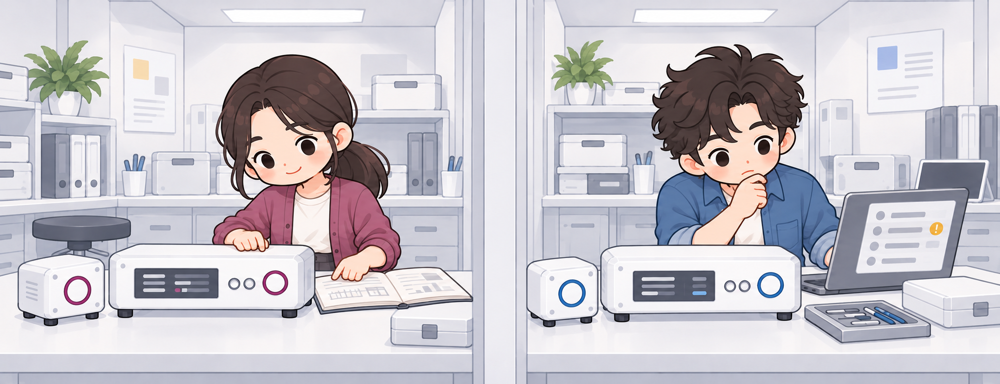


## Resources and Qubit Assignments

The Bell pair is prepared before its qubits are distributed to the two laboratories. After distribution, only local operations on each party's own qubits and **two classical bits sent from Alice to Bob** are available.

| Qubit in the full circuit | Role | Location after distribution |
|---|---|---|
| q0 = Q | Unknown input to be teleported | Alice |
| q1 = A | One half of the Bell pair | Alice |
| q2 = B | The other half of the Bell pair; the output after teleportation | Bob |

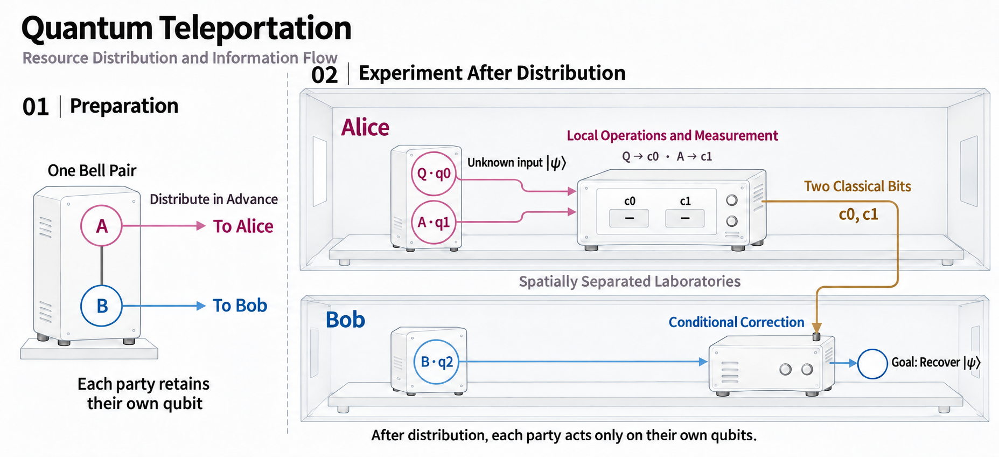

*After distribution, the arrows between the two laboratories represent classical communication carrying Alice's measurement outcomes.*

**Distinguish the qubit indices in the full circuit from those inside each function.** Each function returns one of the small circuits listed below, and the provided code combines them into the full circuit. For example, q0 inside `bob_decoder()` maps to q2 in the full circuit.

| Function | Circuit to return | Local indices → full-circuit indices |
|---|---|---|
| `shared_pair()` | `QuantumCircuit(2)` | Local q0=A → full q1; local q1=B → full q2. The initial state is 00. |
| `alice_encoder()` | `QuantumCircuit(2)` | Local q0=Q → full q0; local q1=A → full q1. |
| `bob_decoder()` | `QuantumCircuit(1, 2)` | Local q0=B → full q2. Local c0 and c1 receive Alice's outcomes. |

**The provided code adds Alice's measurements.** The outcome for Q is stored in c0 and the outcome for A in c1, so the output string is ordered as `c1c0`. For example, `10` means c1=1 and c0=0.

The teleportation functions are given neither the amplitudes of the unknown input nor the circuit that prepared it. The goal is to **recover the input state for every input and every measurement branch**. Run the Setup 2 cell below, then begin Exercise 2-1.


In [ ]:
#@title Setup 2 — Teleportation Experiment Tools
def protocol_1q(pair, alice, bob):
    """Fixed routing: q0=payload, q1=Alice resource, q2=Bob; c0,c1=Alice results."""
    validate_fragment(pair, 2)
    validate_fragment(alice, 2)
    validate_fragment(bob, 1, 2, ("h", "x", "z"), True)
    qc = QuantumCircuit(3, 2)
    qc.compose(pair, [1, 2], inplace=True)
    qc.barrier(label="resource distributed")
    qc.compose(alice, [0, 1], inplace=True)
    qc.measure([0, 1], [0, 1])
    qc.compose(bob, [2], [0, 1], inplace=True)
    return qc

def probe_states():
    states = {}
    for label, gates in [("0", []), ("1", ["x"]), ("+", ["h"]),
                         ("-", ["x", "h"]), ("+i", ["h", "s"]), ("-i", ["h", "sdg"])]:
        qc = QuantumCircuit(1)
        for gate in gates:
            getattr(qc, gate)(0)
        states[label] = qc
    return states

def haar_prep(seed, n=1):
    """Haar-random pure state in dimension 2**n, including entangled states for n=2."""
    rng = np.random.default_rng(seed)
    vector = rng.normal(size=2**n) + 1j * rng.normal(size=2**n)
    vector /= np.linalg.norm(vector)
    qc = QuantumCircuit(n)
    qc.prepare_state(vector, list(range(n)))
    return qc

def sample_fidelity(protocol, prep, inputs=(0,), outputs=(2,), shots=SHOTS, seed=SEED):
    """The referee, not the participant's protocol, prepares U|0> and verifies with U^-1."""
    if prep.num_qubits != len(inputs) or len(inputs) != len(outputs):
        raise ValueError("Input/output dimensions do not match")
    qc = QuantumCircuit(protocol.num_qubits, protocol.num_clbits)
    qc.compose(prep, list(inputs), inplace=True)
    qc.compose(protocol, inplace=True)
    verify = ClassicalRegister(len(outputs), "verify")
    qc.add_register(verify)
    qc.compose(prep.inverse(), list(outputs), inplace=True)
    qc.measure(list(outputs), verify)
    counts = BACKEND.run(compile_for_aer(qc, seed),
                         shots=shots, seed_simulator=seed).result().get_counts()
    indices = [qc.find_bit(bit).index for bit in verify]
    successes = 0
    branches = {}
    for key, count in counts.items():
        ok = all(bit_at(key, i) == 0 for i in indices)
        successes += count * ok
        label = "".join(str(bit_at(key, i)) for i in reversed(range(protocol.num_clbits)))
        good, total = branches.get(label, (0, 0))
        branches[label] = (good + count * ok, total + count)
    return {"fidelity": successes / shots,
            "branches": {k: {"shots": n, "fidelity": g/n} for k, (g, n) in sorted(branches.items())}}

def public_teleport_check(protocol, n=1, random_count=20):
    inputs, outputs = ((0,), (2,)) if n == 1 else ((0, 1), (4, 5))
    cases = probe_states() if n == 1 else {}
    cases.update({f"Haar {s}": haar_prep(s, n) for s in range(random_count)})
    scores = []
    for i, (label, prep) in enumerate(cases.items()):
        result = sample_fidelity(protocol, prep, inputs, outputs, seed=SEED+i)
        scores.append(result["fidelity"])
        if i < 6:
            print(f"{label:>8s}: F_hat={scores[-1]:.6f}")
    print(f"{len(scores)} states: mean={np.mean(scores):.6f}, min={min(scores):.6f}")
    return scores

def broken_parts():
    pair = QuantumCircuit(2)
    pair.h(0)
    pair.cx(0, 1)
    alice = QuantumCircuit(2)
    alice.cx(0, 1)
    alice.h(0)
    bob = QuantumCircuit(1, 2)
    with bob.if_test((bob.clbits[0], 1)):
        bob.x(0)
    with bob.if_test((bob.clbits[1], 1)):
        bob.z(0)
    return pair, alice, bob

def graph_pair():
    """Fixed resource: CZ|++>; CZ is expanded using H,CX,H."""
    qc = QuantumCircuit(2)
    qc.h(1)  # Bob's state BEFORE entanglement generation
    qc.h(0)
    qc.h(1)
    qc.cx(0, 1)
    qc.h(1)
    return qc

def protocol_2q(pair4, alice, bob2):
    """Resource local indices [A0,A1,B0,B1] -> global [2,3,4,5]."""
    validate_fragment(pair4, 4)
    validate_fragment(alice, 2)
    validate_fragment(bob2, 2, 4, ("h", "x", "z"), True)
    qc = QuantumCircuit(6, 4)
    qc.compose(pair4, [2, 3, 4, 5], inplace=True)
    qc.barrier(label="resource distributed")
    qc.compose(alice, [0, 2], inplace=True)
    qc.compose(alice, [1, 3], inplace=True)
    qc.measure([0, 2, 1, 3], [0, 1, 2, 3])
    qc.compose(bob2, [4, 5], [0, 1, 2, 3], inplace=True)
    return qc

def report_transfer_check(report, case, exercise):
    """Show a real failed assertion without interrupting the rest of the workbook."""
    from html import escape
    from IPython.display import HTML, display
    observed = report["fidelity"]
    message = (f"[QFF-{exercise}] Input: {case}. "
               f"Ideal teleportation check failed: expected F_hat=1.000000, observed F_hat={observed:.6f}.")
    try:
        assert observed == 1.0, message
    except AssertionError as error:
        display(HTML('<div style="border-left:5px solid #b44b40;background:#fff1ef;padding:14px 18px;">'
                     '<b>Verification failed · AssertionError</b><pre style="white-space:pre-wrap;">'
                     + escape(str(error)) + '</pre>'
                     '<p>This is an intentional debugging experiment, not an installation error. '
                     'Record the failing input and its result, then trace the cause in the circuit below.</p></div>'))
        return False
    print(f"[QFF-{exercise}] PASS — {case}: F_hat={observed:.6f}")
    return True

## 2-1. Reproducing and Diagnosing the Fault · 6 points

**First, run the Run 2-1 cell immediately below and inspect the `AssertionError` message from the provided faulty circuit.** This failure is an intentional part of the debugging exercise. Identify the fault by comparing the six inputs `0`, `1`, `+`, `-`, `+i`, and `-i`, together with the four measurement branches for the `+` input. You will implement the repaired circuits in Exercise 2-2.

The input labels `+i` and `-i` denote $|+i\rangle=(|0\rangle+i|1\rangle)/\sqrt2$ and $|-i\rangle=(|0\rangle-i|1\rangle)/\sqrt2$, respectively.

Implement `teleportation_diagnosis()` in the TODO code cell below.

**Return format:** `(failed_inputs, masked_inputs, plus_branch_fidelities)`

| Return value | Contents and ordering |
|---|---|
| `failed_inputs` | A tuple of input labels for which the faulty circuit has an average fidelity below 1. |
| `masked_inputs` | A tuple of input labels for which the faulty circuit has an average fidelity of 1, masking the fault. |
| `plus_branch_fidelities` | A tuple of four conditional fidelities for the `+` input, corresponding to the outcomes `c1 c0 = 00, 01, 10, 11`. |

Partition all six input labels between `failed_inputs` and `masked_inputs`, including each label exactly once. The labels within either tuple may appear in any order. Here, the average is **weighted by the probabilities of the measurement branches**. A conditional fidelity compares the normalized state in the corresponding branch with the input state. Calculate exact values from the provided faulty circuit; do not copy the sample estimates from the experiment below.

**Grading criteria:** Classification of all six inputs and the numerical results for all four branches.


In [ ]:
with _qff_experiment("Provided experiment 38"):
    #@title Run 2-1 — Reproduce the Fault First — Start with the Error Message
    # Click ▶ first. This provided code reproduces the failure.
    # After identifying the cause, implement the three repaired circuits in the 'Exercise 2-2' answer cells.
    pair_bad = QuantumCircuit(2)
    pair_bad.h(0)
    pair_bad.cx(0, 1)
    
    alice_bad = QuantumCircuit(2)
    alice_bad.cx(0, 1)
    alice_bad.h(0)
    
    bob_bad = QuantumCircuit(1, 2)
    with bob_bad.if_test((bob_bad.clbits[0], 1)):
        bob_bad.x(0)
    with bob_bad.if_test((bob_bad.clbits[1], 1)):
        bob_bad.z(0)
    
    broken = protocol_1q(pair_bad, alice_bad, bob_bad)
    debug_report_2_1 = sample_fidelity(broken, probe_states()["+"])
    debug_passed_2_1 = report_transfer_check(debug_report_2_1, "|+>", "2-1")
    display(broken.draw("mpl", fold=100, cregbundle=False))
    print("Additional evidence: results for six inputs sent through the same circuit")
    for label, prep in probe_states().items():
        print(label, sample_fidelity(broken, prep)["fidelity"])
    print("|+> branch report (c1 c0):")
    show_fidelity(debug_report_2_1)


In [ ]:
# Exercise 2-1 — Write Code Only Between TODO BEGIN and TODO END
def teleportation_diagnosis():
    failed_inputs = masked_inputs = plus_branch_fidelities = None
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("teleportation_diagnosis")
    # TODO END
    return failed_inputs, masked_inputs, plus_branch_fidelities


**Experiment Notes 2-1 · Ungraded**

- Compare the failure message with the results for all six inputs. Which inputs reveal the fault, and which mask it?
- Explain the fault in the circuit using the fidelities obtained for the four measurement branches of the `+` input.

Observations, calculations, and interpretation:

…


## 2-2. Repairing the Teleportation Circuit · 18 points

Complete `shared_pair()`, `alice_encoder()`, and `bob_decoder()` to achieve teleportation with **$F=1$ for every input and every measurement branch**. The numbers of qubits and classical bits, and the local indices in each returned circuit, must follow the table in “Resources and Qubit Assignments” above.

- `shared_pair()` prepares $|\Phi^+\rangle$ from 00.
- `alice_encoder()` returns the operations on local qubits `[Q, A]` before measurement.
- `bob_decoder()` returns `QuantumCircuit(1, 2)`. Here q0 is Bob's qubit, c0 and c1 hold Alice's measurement outcomes, and you may use H/X/Z and `if_test`.

Write each `if_test` condition by **comparing a single classical bit in this circuit with 0 or 1**, as in `with qc.if_test((qc.clbits[i], 1)):`. You may nest `if_test` blocks when a condition depends on multiple bits. Comparing an entire classical register, such as `qc.cregs[0]`, with an integer is not allowed, nor is using a classical logic expression as the condition. The same restriction applies to Bob's corrections in Exercise 2-4(b) and optional Exercise 2-5.

The “Run 2-2 — Verify the Repair — Repaired Circuits and Teleportation Fidelity” cell below combines the three circuits, adds Alice's measurements, and estimates the teleportation fidelity after Bob's corrections from measurement samples. Use this output to check your repair.

**Grading criteria:** Preparation of the Bell resource and the complete teleportation channel. The grader checks whether an arbitrary unknown input is recovered in every measurement branch. Alternative circuits and correction orders that implement the same behavior are accepted.


In [ ]:
# Exercise 2-2 — Write Code Only Between TODO BEGIN and TODO END
def shared_pair():
    "A 2-qubit circuit that prepares Phi+ from 00."
    qc = QuantumCircuit(2)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("shared_pair")
    # TODO END
    return qc


In [ ]:
# Exercise 2-2 — Write Code Only Between TODO BEGIN and TODO END
def alice_encoder():
    "A 2-qubit circuit in Q,A order. Do not include measurements."
    qc = QuantumCircuit(2)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("alice_encoder")
    # TODO END
    return qc


In [ ]:
# Exercise 2-2 — Write Code Only Between TODO BEGIN and TODO END
def bob_decoder():
    "QuantumCircuit(1, 2), q0=Bob, c0/c1=Alice's outcomes."
    qc = QuantumCircuit(1, 2)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("bob_decoder")
    # TODO END
    return qc


In [ ]:
#@title Run 2-2 — Verify the Repair — Repaired Circuits and Teleportation Fidelity
def inspect_fixed():
    protocol = protocol_1q(shared_pair(), alice_encoder(), bob_decoder())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    return public_teleport_check(protocol)

fixed_results = run_if_ready(inspect_fixed)

**Experiment Notes 2-2 · Ungraded**

- Calculate Bob's state before correction for each measurement outcome `c1c0 = 00, 01, 10, 11`, and list it together with the correction you applied.
- What changes if the order of the X and Z corrections is reversed? Explain your answer in relation to the verification results for the repaired circuit.

Observations, calculations, and interpretation:

…


## 2-3. Interpreting Teleportation Verification · 7 points

The output of Exercise 2-2 shows fidelity estimates for six reference states and 20 Haar-random pure states. After examining these results, implement `teleportation_validation()`, distinguishing **teleportation performance after correction** from **Bob's average state before correction**.

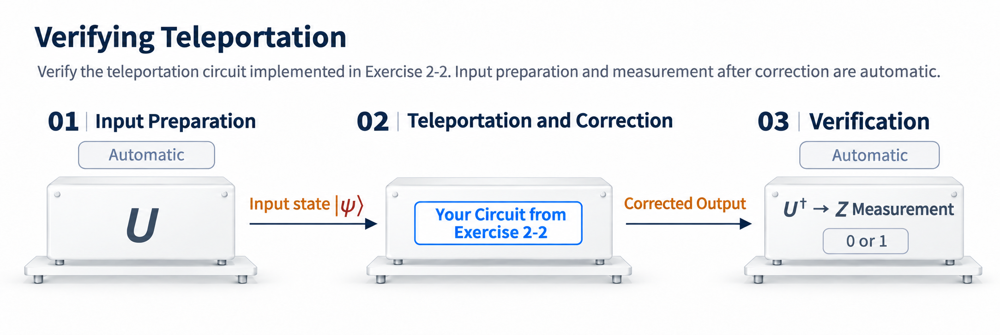

The provided verification code knows the operation $U$ used to prepare the input, so it applies $U^\dagger$ to Bob's corrected output and then measures in the Z basis. **The probability of measuring 0 equals the fidelity with the original input state.** The preparation information for $U$ is not supplied to the teleportation protocol.

**Return format:** `(mean_F, min_F, bob_average_density)`

| Return value | Quantity to calculate |
|---|---|
| `mean_F` | The arithmetic mean of the 26 ideal fidelities after correction: the six states from `probe_states()` and the states from `haar_prep(seed)` for `seed=0, …, 19`. |
| `min_F` | The minimum of the same 26 fidelities. |
| `bob_average_density` | Bob's 2×2 density matrix in a correct teleportation protocol before receiving Alice's outcomes, averaged over the measurement branches using their probabilities. Use `0` as the reference input. |

**① Fidelity after correction: `mean_F`, `min_F`**

Use the circuits you repaired in Exercise 2-2. For each input $|\psi\rangle$, obtain Bob's density matrix in each of Alice's measurement branches **after applying Bob's correction**, then take the probability-weighted average over the branches to calculate $\rho_B$. The fidelity for that input is $F=\langle\psi|\rho_B|\psi\rangle$. Calculate the mean and minimum over all 26 inputs.

**② Average state before correction: `bob_average_density`**

Calculate this quantity for a **correct teleportation circuit**. For input `0`, obtain Bob's density matrix in each measurement branch **before applying Bob's correction**, then take the probability-weighted average over the branches. Use the row and column order `0, 1`. Return a NumPy array or a nested sequence. You may retain a complex data type or remove imaginary parts that are within numerical precision. In a correct teleportation protocol, this average state must remain the same when the unknown input is changed.

**Distinguish exact values from sample estimates.** The experiment output displays fidelity estimates obtained from repeated measurements. For this exercise, return values calculated from exact probabilities and density matrices, rather than estimates from 4096 shots.

**Grading criteria:** `mean_F` and `min_F` are graded only if the circuits in Exercise 2-2 satisfy the teleportation requirements for every input and measurement branch. `bob_average_density` is assessed against the theoretical average state of a correct teleportation protocol, **independently of whether Exercise 2-2 passes**. You may calculate and submit this average state even if Exercise 2-2 is incomplete; this item does not ask for the average state of an incorrect circuit you are still developing.


In [ ]:
# Exercise 2-3 — Write Code Only Between TODO BEGIN and TODO END
def teleportation_validation():
    mean_F = min_F = bob_average_density = None
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("teleportation_validation")
    # TODO END
    return mean_F, min_F, bob_average_density


**Experiment Notes 2-3 · Ungraded**

- If $U|0\rangle=|\psi\rangle$, why does applying $U^\dagger$ to Bob's corrected output give a probability $P(0)$ equal to $\langle\psi|\rho_B|\psi\rangle$? Could Bob perform this verification himself without knowing the input?
- Can a fidelity estimate from a finite number of measurements equal exactly 1 in ideal teleportation?
- Explain why Alice cannot transmit information to Bob merely by preparing different input states before her classical outcomes reach him.

Observations, calculations, and interpretation:

…


## 2-4. Adapting the Protocol to a Different Resource · 9 points

**(a) Preparing a Bell pair from a different initial state**

The initial state before entanglement generation is $|0\rangle_A|+\rangle_B$. In the “Run 2-4 — Compare Resources — Inspect State Preparation” cell below, observe what happens when H(A) followed by CX(A,B) is applied to this state, and determine whether entanglement is generated. Then implement `bell_pair_from_b_plus()` as a circuit that transforms the same initial state into $|\Phi^+\rangle$.

Return a `QuantumCircuit(2)` with no measurements, containing **the complete transformation to append after the initial state has been prepared**. The local qubits are q0=A and q1=B, and you may use H/X/Z/CX. Choose the order of the gates in your transformation. The grading code prepares B in `+` before applying your circuit. The target state is $|\Phi^+\rangle$.

**What the run cells check:** “Run 2-4 — Compare Resources — Inspect State Preparation” compares the provided fixed circuits; it does not call `bell_pair_from_b_plus()`. The later “Run 2-4 — Check the Corrections — Teleportation with a Graph-State Resource” cell checks only the teleportation in part (b). Successful output from both cells therefore does not verify your answer to part (a). **The circuit returned by `bell_pair_from_b_plus()` is checked in the final grading cell.**

**(b) Corrections for a graph-state resource**

Implement `bob_graph_decoder()` for the fixed resource $|G\rangle=CZ|++\rangle=(I_A\otimes H_B)|\Phi^+\rangle$. Keep `graph_pair()` and **the Alice operations you implemented in Exercise 2-2** unchanged. `bob_graph_decoder()`, like `bob_decoder()`, returns `QuantumCircuit(1, 2)`, and only H/X/Z and `if_test` are allowed. As in Exercise 2-2, each `if_test` condition must compare a single local classical bit with 0 or 1. The tensor-product notation above uses the order A,B.

**Grading criteria:** Bell-state preparation in part (a), and teleportation for every input and measurement branch in part (b).


In [ ]:
# Exercise 2-4 — Write Code Only Between TODO BEGIN and TODO END
def bell_pair_from_b_plus():
    qc = QuantumCircuit(2)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("bell_pair_from_b_plus")
    # TODO END
    return qc


In [ ]:
with _qff_experiment("Provided experiment 49"):
    #@title Run 2-4 — Compare Resources — Inspect State Preparation
    plus_attempt = QuantumCircuit(2)
    plus_attempt.h(1)
    plus_attempt.h(0)
    plus_attempt.cx(0, 1)
    print("CX attempt, Bob purity:", partial_trace(Statevector(plus_attempt), [0]).purity().real)
    print("Graph resource, Bob purity:", partial_trace(Statevector(graph_pair()), [0]).purity().real)
    display(graph_pair().draw("mpl"))


In [ ]:
# Exercise 2-4 — Write Code Only Between TODO BEGIN and TODO END
def bob_graph_decoder():
    "QuantumCircuit(1, 2) for the fixed graph-state resource. H,X,Z and if_test are allowed."
    qc = QuantumCircuit(1, 2)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("bob_graph_decoder")
    # TODO END
    return qc


In [ ]:
#@title Run 2-4 — Check the Corrections — Teleportation with a Graph-State Resource
def inspect_graph():
    protocol = protocol_1q(graph_pair(), alice_encoder(), bob_graph_decoder())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    return public_teleport_check(protocol)

graph_results = run_if_ready(inspect_graph)

**Experiment Notes 2-4 · Ungraded**

- Starting from $|0\rangle_A|+\rangle_B$, does applying H(A) followed by CX(A,B) generate entanglement? Explain and compare this circuit with your Bell-state preparation circuit.
- How did you adapt Bob's corrections when switching to the graph-state resource? Explain which corrections are needed and in what order they are applied.

Observations, calculations, and interpretation:

…


## Bridge Experiment — Teleporting One Share of GHZ

**This provided experiment combines your answer functions from Exercises 1-6 and 2-2 without introducing a new TODO.** It checks whether the repaired device also preserves entanglement. Alice holds q0 and q3 of a GHZ state, while Charlie holds q4. The quantum information carried by q0 must be transferred to Bob's q2 while preserving its entanglement with q3 and q4. Alice's q1 and Bob's q2 share the Bell pair used for teleportation.
The “Bridge Experiment — Teleport One Share of GHZ with the Repaired Circuit” cell below reuses **the preparation function from Exercise 1-6 and the teleportation functions from Exercise 2-2**. Distinguish the two values in its output:

- **Input GHZ preparation fidelity:** Compares the input state prepared in Exercise 1-6 with the target GHZ state.
- **Teleportation fidelity:** Compares the state of Alice(q3), Bob(q2), and Charlie(q4) after teleportation with the input state you actually prepared. This value uses measurement samples to estimate how well the full three-qubit state was preserved.

Check both results to verify that GHZ preparation and teleportation are correct. The resource shared by the three laboratories after teleportation will also be used in the bridge experiment in Part 3.

**The object of verification is the full three-qubit state.** The q0 subsystem of GHZ alone is not a pure single-qubit state. Teleportation success must therefore be assessed by examining correlations with the other qubits, rather than only the individual measurement outcomes for each qubit.


In [ ]:
#@title Bridge Experiment — Teleport One Share of GHZ with the Repaired Circuit
# Provided code: combine the results of Exercises 1-6 and 2-2 without writing a new function.
def linked_ghz_setup():
    prep = validate_fragment(build_ghz_state(), 3)
    transfer = protocol_1q(shared_pair(), alice_encoder(), bob_decoder())
    protocol = QuantumCircuit(5, 2)
    protocol.compose(transfer, [0, 1, 2], [0, 1], inplace=True)
    return prep, protocol

def inspect_linked_ghz():
    prep, protocol = linked_ghz_setup()
    report = sample_fidelity(protocol, prep, inputs=(0, 3, 4), outputs=(2, 3, 4))
    target = Statevector(np.array([1,0,0,0,0,0,0,1])/np.sqrt(2))
    print("Input GHZ preparation fidelity:", state_fidelity(Statevector(prep), target))
    print("Teleportation fidelity of the full prepared three-qubit state (including all c1 c0 branches)")
    show_fidelity(report)
    return report

linked_ghz_result = run_if_ready(inspect_linked_ghz)


**Criteria for completing the teleportation test:** Bob's state must be corrected according to Alice's measurement outcomes to recover the input state, while preserving any entanglement the input shared with other qubits. Next, you will test how the three laboratories use this shared resource without communicating after receiving their inputs.


<a id="part3"></a>

# 3. The GHZ–Mermin Game — Testing Cooperation

The three laboratories must now **produce responses that satisfy a joint condition, using only the input each laboratory receives**. They cannot communicate after receiving their inputs. Compare the average winning probabilities of a classical strategy agreed upon in advance and a quantum strategy using a GHZ state.

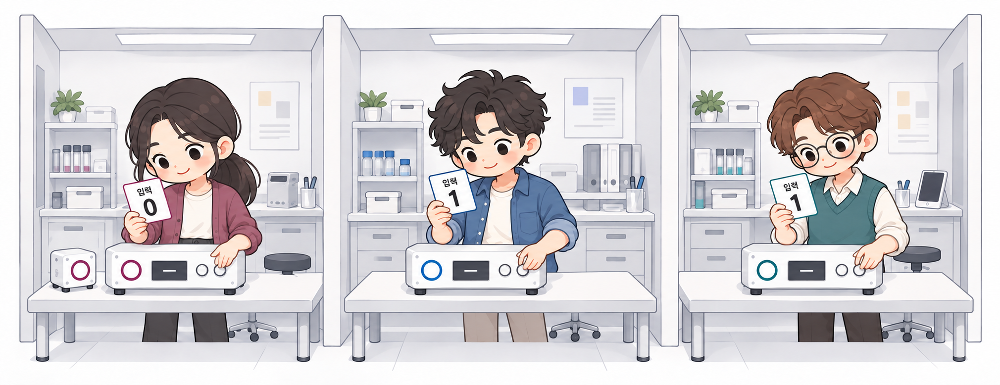

*This example shows a round in which the allowed input 011 is selected. Alice sees only 0, Bob only 1, and Charlie only 1. No participant can see the inputs received by the other laboratories.*

The score for winning a round is separate from the points assigned to exercises in this notebook. In the game, the team earns one point when the three participants' joint response satisfies the winning condition.


## Game Rules — Preparation, Inputs, Responses, and Evaluation

**The inputs $x,y,z$ are classical bits sent by the referee to the laboratories**, not initial qubit states or measurement outcomes. Alice receives $x$, Bob receives $y$, and Charlie receives $z$; they produce output bits $a,b,c$, respectively.

1. **Preparation:** Each participant decides in advance what to do for input 0 and input 1. Prior agreement and shared randomness are allowed. For a quantum strategy, a GHZ state is prepared at this stage, and one qubit is distributed to each participant.
2. **Input distribution:** The referee selects one of `xyz = 000, 011, 101, 110`, **each with probability 1/4**. This choice is independent of the resources shared beforehand. Each participant receives only their own input bit.
3. **Individual responses:** No communication is allowed after the inputs are received. A classical strategy uses predetermined output rules; a quantum strategy uses local measurements chosen according to each participant's own input.
4. **Joint evaluation:** Once all three participants have responded, the referee collects $a,b,c$ and evaluates the condition below. The team earns one point for a win and zero points for a loss.

| Input `xyz` | Number of 1s required in the output `abc` to win | Output parity |
|---|---|---|
| `000` | 0 or 2 — even | 0 |
| `011`, `101`, `110` | 1 or 3 — odd | 1 |

For example, if the input is `011` and the response `abc` is `001`, the team wins because the response contains one 1. For the same input, `abc=000` loses. This is an example of evaluating a single round; a strategy must be specified in advance for every allowed input.

The winning condition can be written as follows, where $\oplus$ denotes the exclusive OR (XOR) of bits.

$$a\oplus b\oplus c=\frac{x+y+z}{2}\pmod2.$$

The average winning probability is the equally weighted average of the winning probabilities for the four allowed inputs. The provided game experiments use **4096 shots for each input**, so the mean of the four empirical winning probabilities equals the total number of wins divided by the total number of trials. Each round of a quantum experiment uses a newly prepared shared resource.

**Qubit assignment:** For the directly prepared GHZ state, Alice, Bob, and Charlie use q0, q1, and q2, respectively. In the Bridge Experiment from Part 2, they use q3, q2, and q4 in the same participant order. A local measurement outcome of +1 corresponds to output bit 0, and an outcome of −1 corresponds to output bit 1.

Run the Setup 3 cell below, then begin by investigating classical strategies.


In [ ]:
#@title Setup 3 — Game Experiment Tools
INPUTS = ((0,0,0), (0,1,1), (1,0,1), (1,1,0))
PARTIES = ("Alice", "Bob", "Charlie")

def winning_parity(x, y, z):
    if (x, y, z) not in INPUTS:
        raise ValueError("Only promised input triples are used")
    return ((x + y + z) // 2) % 2

def freeze_strategy(local_basis):
    """Build six local circuits once, BEFORE the referee selects any input triple."""
    table = {}
    for party in PARTIES:
        for bit in (0, 1):
            table[party, bit] = validate_fragment(
                local_basis(party, bit), 1, allowed=("h", "s", "sdg", "x", "z")).copy()
    return table

def game_unitary(resource, strategy, xyz):
    validate_fragment(resource, resource.num_qubits)
    if resource.num_qubits not in (3, 4):
        raise ValueError("Expected 3 players, with optional inaccessible q3")
    if xyz not in INPUTS:
        raise ValueError("Invalid input triple")
    qc = resource.copy()
    qc.barrier(label="inputs distributed")
    for q, (party, bit) in enumerate(zip(PARTIES, xyz)):
        fragment = validate_fragment(strategy[party, bit], 1,
                                     allowed=("h", "s", "sdg", "x", "z"))
        qc.compose(fragment, [q], inplace=True)
    return qc

def build_mermin_round(resource, strategy, xyz):
    qc = game_unitary(resource, strategy, xyz)
    out = ClassicalRegister(3, "out")
    qc.add_register(out)
    qc.measure([0, 1, 2], out)
    return qc

def sample_game(resource, strategy, shots=SHOTS, seed=SEED):
    rows = []
    circuits = [build_mermin_round(resource, strategy, xyz) for xyz in INPUTS]
    result = BACKEND.run(compile_for_aer(circuits, seed),
                         shots=shots, seed_simulator=seed).result()
    for i, xyz in enumerate(INPUTS):
        counts = result.get_counts(i)
        wins = sum(n for key, n in counts.items()
                   if sum(map(int, key.replace(" ", ""))) % 2 == winning_parity(*xyz))
        ev = sum((-1)**sum(map(int, key.replace(" ", ""))) * n for key, n in counts.items())/shots
        rows.append({"input": xyz, "win_rate": wins/shots, "correlator": ev})
    # This is the game Bell expression for the submitted observables.
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([r["win_rate"] for r in rows]), "M": m}

def exact_game(resource, strategy):
    rows = []
    for xyz in INPUTS:
        probabilities = Statevector.from_instruction(game_unitary(resource, strategy, xyz)).probabilities([0, 1, 2])
        ev = sum((-1)**i.bit_count()*p for i, p in enumerate(probabilities))
        rows.append({"input": xyz, "win_rate": (1+(-1)**winning_parity(*xyz)*ev)/2, "correlator": ev})
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([r["win_rate"] for r in rows]), "M": m}

def coin_resource():
    """q3 purifies the mixture and is inaccessible to all three players."""
    qc = QuantumCircuit(4)
    qc.h(3)
    for q in (0, 1, 2):
        qc.cx(3, q)
    return qc

def sample_linked_game(strategy, shots=SHOTS, seed=SEED):
    """Use all teleportation branches; only final game bits determine the score."""
    prep, protocol = linked_ghz_setup()
    circuits = []
    for xyz in INPUTS:
        qc = QuantumCircuit(5, 2)
        qc.compose(prep, [0, 3, 4], inplace=True)
        qc.compose(protocol, inplace=True)
        qc.barrier(label="inputs distributed")  # Transfer/corrections are already complete.
        for q, party, bit in zip((3, 2, 4), PARTIES, xyz):  # Alice, Bob, Charlie
            qc.compose(validate_fragment(strategy[party, bit], 1,
                       allowed=("h", "s", "sdg", "x", "z")), [q], inplace=True)
        out = ClassicalRegister(3, "out")
        qc.add_register(out)
        qc.measure([3, 2, 4], out)
        circuits.append(qc)
    result = BACKEND.run(compile_for_aer(circuits, seed), shots=shots,
                         seed_simulator=seed).result()
    rows = []
    for i, xyz in enumerate(INPUTS):
        counts = result.get_counts(i)
        wins, signed = 0, 0
        for key, count in counts.items():
            parity = sum(bit_at(key, j) for j in (2, 3, 4)) % 2
            wins += count * (parity == winning_parity(*xyz))
            signed += count * (-1)**parity
        rows.append({"input": xyz, "win_rate": wins/shots, "correlator": signed/shots})
    m = rows[0]["correlator"] - sum(row["correlator"] for row in rows[1:])
    return {"rows": rows, "p_win": np.mean([row["win_rate"] for row in rows]), "M": m}


## 3-1. Limits of Classical Strategies · 7 points

Represent one participant's strategy as `(output for input 0, output for input 1)`. In `classical_search()`, **examine all 64 combinations of deterministic strategies** for the three participants and return `(maximum winning probability, (sa, sb, sc))`. Each strategy is a pair containing the output bits for inputs 0 and 1, in that order. The strategies `sa`, `sb`, and `sc` belong to Alice, Bob, and Charlie, respectively. The winning probability is averaged over the four equally likely allowed inputs.

Find the best classical strategy to establish a benchmark for the quantum strategy.

**Grading criteria:** The returned maximum winning probability, a strategy that achieves it, and consistency between these two results. Any strategy attaining the same maximum is accepted.


In [ ]:
# Exercise 3-1 — Write Code Only Between TODO BEGIN and TODO END
def classical_search():
    "Check all 64 combinations and return (best_probability, (sa,sb,sc))."
    best_probability = None
    sa = sb = sc = None
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("classical_search")
    # TODO END
    return best_probability, (sa, sb, sc)


In [ ]:
#@title Run 3-1 — Check the Maximum Classical Winning Probability
classical_result = run_if_ready(classical_search)
print("classical result:", classical_result)

**Experiment Notes 3-1 · Ungraded**

- Give an example of an optimal classical strategy you found, and identify the allowed inputs for which it wins or loses.
- Use parity to explain why no classical strategy can win for every input, and explain why shared randomness cannot increase the classical bound.

Observations, calculations, and interpretation:

…


## 3-2. A GHZ Measurement Strategy · 10 points

Prepare GHZ+ using `build_ghz3()`, and use the properties below to design `local_basis(party, input_bit)`.

$$\langle XXX\rangle=+1,\qquad \langle XYY\rangle=\langle YXY\rangle=\langle YYX\rangle=-1.$$

`build_ghz3()` must return a `QuantumCircuit(3)` with no measurements, using **only H/X/Z/CX**. The additional permission to use S/S† applies only to `local_basis()` below. For `party` equal to `"Alice"`, `"Bob"`, or `"Charlie"` and `input_bit` equal to 0 or 1, `local_basis()` must return a `QuantumCircuit(1)` with no measurements, using H/X/Z/S/S†. Each participant's circuit must depend only on that participant's name and input bit. Specify the circuits for inputs 0 and 1 for each of the three participants—a total of six circuits—before the game's input combination is selected.

In `local_basis()`, include **only the basis change gates applied before measurement** to implement the desired measurement. The provided experiment code adds a Z basis measurement after this circuit and uses the measurement outcome 0/1 as the participant's output bit.

**Hint:** An X measurement is implemented by H followed by a Z measurement; a Y measurement is implemented by S† → H followed by a Z measurement.

**Grading criteria:** Preparation of GHZ+ and satisfaction of the joint winning condition for all four inputs. You must implement both GHZ+ preparation and the appropriate basis changes before measurement for each input.

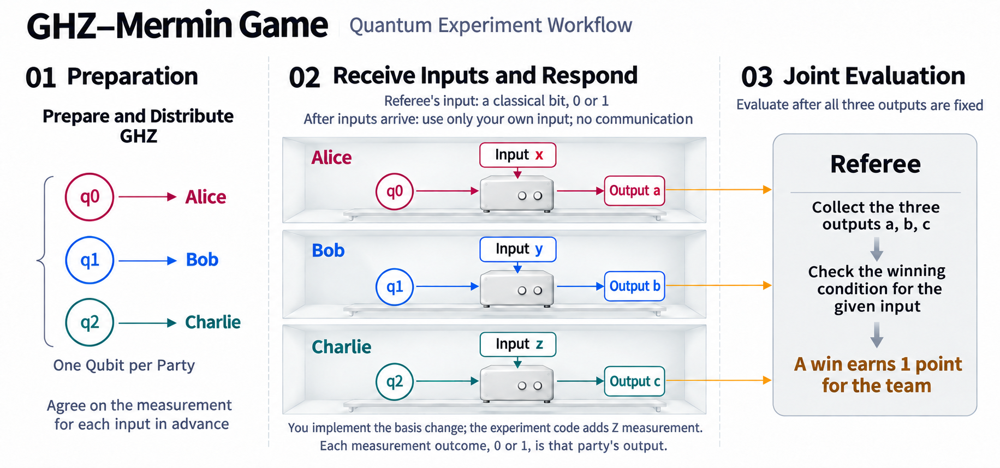

*One round of the quantum strategy. GHZ preparation and the choice of measurement for each input are completed before the inputs are distributed. The three responses are evaluated jointly only after all participants have responded.*

In 3-2, check the preparation circuit and measurement strategy. In 3-3, examine the results of repeated trials and the winning probabilities.


In [ ]:
# Exercise 3-2 — Write Code Only Between TODO BEGIN and TODO END
def build_ghz3():
    "A 3-qubit circuit that prepares GHZ+ from 000. Do not include measurements."
    qc = QuantumCircuit(3)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("build_ghz3")
    # TODO END
    return qc


In [ ]:
# Exercise 3-2 — Write Code Only Between TODO BEGIN and TODO END
def local_basis(party, input_bit):
    "A 1-qubit basis transformation using only the party's identity and own input."
    qc = QuantumCircuit(1)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("local_basis")
    # TODO END
    return qc


In [ ]:
#@title Run 3-2 — Check GHZ Preparation and Local Measurements
def inspect_strategy():
    resource = validate_fragment(build_ghz3(), 3)
    target = Statevector(np.array([1,0,0,0,0,0,0,1])/np.sqrt(2))
    print("GHZ preparation fidelity:", state_fidelity(Statevector(resource), target))
    strategy = freeze_strategy(local_basis)
    display(resource.draw("mpl"))
    for party in PARTIES:
        for bit in (0, 1):
            print(f"{party} input: {bit}")
            display(strategy[party, bit].draw("mpl"))
    display(build_mermin_round(resource, strategy, (0, 1, 1)).draw("mpl", fold=100))

run_if_ready(inspect_strategy)

**Experiment Notes 3-2 · Ungraded**

- State the observable each participant measures for inputs 0 and 1, and list the gates that implement each measurement in the order they are applied.
- Explain how the chosen measurements and GHZ correlations satisfy the joint winning condition for each of the four allowed inputs.

Observations, calculations, and interpretation:

…


## Reading Game Result Bitstrings

We write the inputs as `xyz` and the responses in participant order as `abc`. Qiskit displays game measurement outcomes from the highest index to the lowest, so they appear in **`cba` order**.

| Experiment | Raw counts key | Bits used to compute winning probability and parity |
|---|---|---|
| Directly prepared GHZ state | `cba` | All three game output bits |
| Bridge Experiment from Part 2 | `cba c1c0` | Only the first three game output bits, `cba` |

The trailing `c1c0` in the Bridge Experiment contains Alice's teleportation measurement outcomes, not game responses. The provided game tools include all teleportation measurement branches and compute parity and winning probability using only the three game output bits. GHZ preparation fidelity and game winning probability are also separate quantities to check.


## 3-3. Winning Probability and the Mermin Value · 7 points

In `mermin_report()`, **calculate and return the correlator and winning probability for each of the four inputs using exact probabilities**, with $E_{xyz}=\langle(-1)^{a+b+c}\rangle$. The provided experiment below displays both empirical results from 4096 shots per input and exact calculations. Compare the two.

$$M_{game}=E_{000}-E_{011}-E_{101}-E_{110}.$$

Implement `mermin_report()` in the TODO code cell below. Use **the GHZ preparation circuit and the six basis change circuits you implemented in 3-2**.

**Return format:** `(E, win_rates, M, p_win)`

- `E`: Four exact correlators, in input order `000, 011, 101, 110`.
- `win_rates`: Four exact winning probabilities, in the same input order.
- `M`: The Mermin game value calculated using the expression above.
- `p_win`: The winning probability averaged equally over the four inputs.

Return `E` and `win_rates` as tuples of length 4. You may implement the probability calculations in any way you choose, including by using the provided tools for exact calculations.

**Grading criteria:** The numerical results for all four inputs, the overall M value, and the average winning probability. These numerical answers are graded **only if the GHZ+ preparation and measurement strategy in 3-2 satisfy the requirements**.

| Average winning probability | M value | Interpretation |
|---|---:|---|
| 75% | 2 | Average performance of the best classical strategy |
| Above 75% | Above 2 | Exceeds the average performance achievable with shared randomness and prior agreement alone |
| 100% | 4 | Satisfies the joint winning condition for every allowed input |

The classical bound of 75% in the table applies to the theoretical average winning probability when the four inputs are equally likely. An empirical winning probability from a finite number of trials may exceed 75% because of sampling fluctuations.

The cell below, “Run 3-3 — Check Winning Probabilities and M for All Four Inputs,” displays the exact and empirical results for the directly prepared GHZ state, together with **empirical results for the GHZ state transmitted in Part 2**. You can test the directly prepared GHZ state even if Part 2 is incomplete. The calculations in `mermin_report()` concern the directly prepared resource from 3-2.

This run cell computes comparison results separately and **does not call `mermin_report()`**. Displaying experiment results therefore does not verify that this TODO function is complete or that its return values are correct. Its return values are checked in the final grading cell.


In [ ]:
# Exercise 3-3 — Write Code Only Between TODO BEGIN and TODO END
def mermin_report():
    E = win_rates = M = p_win = None
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("mermin_report")
    # TODO END
    return E, win_rates, M, p_win


In [ ]:
#@title Run 3-3 — Check Winning Probabilities and M for All Four Inputs
def inspect_game():
    resource = validate_fragment(build_ghz3(), 3)
    strategy = freeze_strategy(local_basis)
    sampled = sample_game(resource, strategy)
    exact = exact_game(resource, strategy)
    print("4096 shots / input")
    show_game(sampled)
    print("exact probabilities")
    show_game(exact)
    return sampled, exact

game_results = run_if_ready(inspect_game)

def inspect_linked_game():
    strategy = freeze_strategy(local_basis)
    report = sample_linked_game(strategy)
    print("Q-LINK: cooperative test using the GHZ state teleported in Part 2 (4096 shots / input)")
    show_game(report)
    return report

linked_game_result = run_if_ready(inspect_linked_game)

**Experiment Notes 3-3 · Ungraded**

- Derive $p_{win}=1/2+M_{game}/8$, and compare your calculated M and average winning probability with the classical benchmark.
- Compare the exact and empirical results for the directly prepared GHZ state. If you also completed the Bridge Experiment, include the empirical results for the transmitted GHZ state in your comparison.

Observations, calculations, and interpretation:

…


## 3-4. Replacing the Shared Resource · 6 points

GHZ and Coin had the same theoretical Z measurement distribution in 1-6. Will they also perform equally well in this cooperation test? **Keep each participant's measurement choices for inputs 0 and 1 from 3-2 fixed, and change only the shared resource.** Keep the input distribution and winning condition unchanged as well.

| Shared resource | Preparation function | Measurement strategy | Quantities to calculate |
|---|---|---|---|
| GHZ⁺ | `build_ghz3()` | The strategy implemented in 3-2 | Exact M and average winning probability |
| Coin | Provided `coin_resource()` | The same strategy | Exact M and average winning probability |

Coin prepares 000 or 111, each with probability 1/2. Qubit q3 is a record qubit that is inaccessible after preparation.

Implement `resource_comparison()` and return the following:

**Return format:** `(ghz_M, ghz_p_win, coin_M, coin_p_win, classical_best)`

The first four values are obtained by applying **the same measurement strategy from 3-2** to the two resources in the table.

**Classical benchmark `classical_best`:** This is the **maximum average winning probability over all classical strategies** that specify each participant's output bit for inputs 0 and 1, as in 3-1. These include strategies that choose output bits without using measurement outcomes. You may use the search result from 3-1. Distinguish this value from the winning probability obtained by applying the measurement strategy from 3-2 to Coin.

**Grading criteria:** The exact numerical results for both resources and the performance of the best classical strategy. The first four values are graded **only if the GHZ⁺ preparation and measurement strategy in 3-2 satisfy the requirements**. `classical_best` is graded independently of this condition.

**What the run cells check:** The two run cells below compute comparison results directly from the circuits and do not call `resource_comparison()`. Whether this function is complete and whether its return values are correct are checked in the final grading cell.


In [ ]:
# Exercise 3-4 — Write Code Only Between TODO BEGIN and TODO END
def resource_comparison():
    ghz_M = ghz_p_win = coin_M = coin_p_win = classical_best = None
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("resource_comparison")
    # TODO END
    return ghz_M, ghz_p_win, coin_M, coin_p_win, classical_best


In [ ]:
#@title Run 3-4 — Experiment with the Coin Resource
def inspect_coin():
    strategy = freeze_strategy(local_basis)
    resource = coin_resource()
    rho = partial_trace(Statevector(resource), [3])
    print("coin reduced-state purity:", rho.purity().real)
    print("sampled coin strategy")
    show_game(sample_game(resource, strategy))
    print("exact coin strategy")
    show_game(exact_game(resource, strategy))

run_if_ready(inspect_coin)

*The left plot shows the winning probability for each input; the right plot shows the average over the four equally likely inputs. The classical bound of 75% applies to the theoretical average on the right. The Coin bars use the measurement strategy from 3-2; distinguish these results from the performance of the best classical output strategy.*


In [ ]:
#@title Run 3-4 — Compare the Two Resources — Winning-Probability Plots
def compare_game_resources():
    resource = validate_fragment(build_ghz3(), 3)
    strategy = freeze_strategy(local_basis)
    quantum = sample_game(resource, strategy)
    coin = sample_game(coin_resource(), strategy)
    plot_game_comparison(quantum, coin)

run_if_ready(compare_game_resources)

**Experiment Notes 3-4 · Ungraded**

- Explain why GHZ and Coin, despite having the same Z measurement distribution, yield different correlators and winning probabilities under the same measurement strategy from 3-2.
- Explain why the winning probability obtained by applying the fixed measurement strategy to Coin and `classical_best` represent different comparisons.

Observations, calculations, and interpretation:

…


<a id="optional"></a>

# Optional Extensions · 20 additional points

In addition to the 100 points available for the core exercises, 2-5 offers **12 additional points** and 3-5 offers **8 additional points**. Complete 2-2 before attempting 2-5, and 3-2 before attempting 3-5. You may submit either or both optional exercises. Leaving an optional exercise unsubmitted does not reduce your core score.


## 2-5. Optional · Transmitting Two Qubits and Their Correlations · 12 additional points

**First run the cell below, “Run 2-5 — Reproduce the Faults — Start from the Error Message,” and identify the two faults in the resource connections and correction targets.** Prepare the shared resource for each transmission path as a $|\Phi^+\rangle$ Bell pair, as in 2-2. Use two such pairs and four classical bits to transmit the full state of the two input qubits.

- In the full circuit, `q0, q1, q2, q3, q4, q5` correspond to `Q0, Q1, A0, A1, B0, B1`, respectively.
- Measurement outcomes are stored as `Q0→c0`, `A0→c1`, `Q1→c2`, and `A1→c3`.
- `shared_pairs_2q()` must return a `QuantumCircuit(4)` with no measurements, in local order `[A0, A1, B0, B1]`.
- `bob_decoder_2q()` must return a `QuantumCircuit(2, 4)` in local order `[B0, B1]`. Use only H/X/Z and `if_test`, and preserve the output order. As in 2-2, each `if_test` condition must compare a single classical bit of this circuit with 0 or 1. To check conditions on several bits together, nest single-bit conditional blocks.

Reuse your `alice_encoder()` from 2-2 to verify the corrected implementation. The verification cell below uses Bell states and Haar-random pure states as inputs to check the fidelity of the full two-qubit state.

**Grading criteria:** Correct preparation of the two Bell resources and transmission of the full two-qubit state. All 16 measurement branches are checked. The correlations of entangled inputs and the output order must be preserved.


In [ ]:
with _qff_experiment("Provided experiment 78"):
    #@title Run 2-5 — Reproduce the Faults — Start from the Error Message
    bad_pair4 = QuantumCircuit(4)
    bad_pair4.h(0)
    bad_pair4.cx(0, 1)
    bad_pair4.h(2)
    bad_pair4.cx(2, 3)
    bad_bob2 = QuantumCircuit(2, 4)
    with bad_bob2.if_test((bad_bob2.clbits[0], 1)):
        bad_bob2.z(1)
    with bad_bob2.if_test((bad_bob2.clbits[1], 1)):
        bad_bob2.x(1)
    with bad_bob2.if_test((bad_bob2.clbits[2], 1)):
        bad_bob2.z(0)
    with bad_bob2.if_test((bad_bob2.clbits[3], 1)):
        bad_bob2.x(0)
    _, alice_for_debug, _ = broken_parts()
    broken2 = protocol_2q(bad_pair4, alice_for_debug, bad_bob2)
    debug_report_2_5 = sample_fidelity(broken2, haar_prep(0, 2), (0, 1), (4, 5))
    debug_passed_2_5 = report_transfer_check(debug_report_2_5, "2-qubit Haar seed=0", "2-5")
    display(broken2.draw("mpl", fold=100, cregbundle=False))
    show_fidelity(debug_report_2_5)


In [ ]:
# Exercise 2-5 — Write Code Only Between TODO BEGIN and TODO END
def shared_pairs_2q():
    "A 4-qubit resource circuit in A0,A1,B0,B1 order."
    qc = QuantumCircuit(4)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("shared_pairs_2q")
    # TODO END
    return qc


In [ ]:
# Exercise 2-5 — Write Code Only Between TODO BEGIN and TODO END
def bob_decoder_2q():
    "A conditional correction circuit with 2 qubits in B0,B1 order and 4 classical bits."
    qc = QuantumCircuit(2, 4)
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("bob_decoder_2q")
    # TODO END
    return qc


In [ ]:
#@title Run 2-5 — Verify the Repair — Joint Fidelity
def inspect_two():
    protocol = protocol_2q(shared_pairs_2q(), alice_encoder(), bob_decoder_2q())
    display(protocol.draw("mpl", fold=100, cregbundle=False))
    bell_payload = QuantumCircuit(2)
    bell_payload.h(0)
    bell_payload.cx(0, 1)
    print("Bell payload:")
    show_fidelity(sample_fidelity(protocol, bell_payload, (0, 1), (4, 5)))
    return public_teleport_check(protocol, n=2)

two_qubit_results = run_if_ready(inspect_two)

**Experiment Notes 2-5 · Ungraded**

- Describe the two faults you found in the resource connections and correction targets of the provided circuit, and explain your corrections.
- Record the fidelity of the full two-qubit state for Bell-state and Haar-random pure-state inputs. Why is it insufficient to check only the reduced state of each qubit separately?

Observations, calculations, and interpretation:

…


## 3-5. Optional · Can the Strategy Exceed the Classical Benchmark with Phase Errors? · 8 additional points

Before the GHZ state is distributed, a Z error occurs on Alice's qubit with probability $p$. Whether an error occurred is not revealed, and the X/Y measurement strategy implemented in 3-2 remains fixed.

$$\rho(p)=(1-p)|GHZ^+\rangle\langle GHZ^+|+p|GHZ^-\rangle\langle GHZ^-|.$$

Implement the calculations in `phase_noise_metrics()` in the optional TODO below. The four elements of the returned tuple must contain the results for the four error probabilities specified below, in the given order.

**Return format:** A tuple containing four `(M, p_win)` pairs, in the order $p=0,\ 0.1,\ 0.25,\ 0.5$. The outer tuple has length 4, and each inner tuple has length 2. `p_win` is the winning probability averaged equally over the four allowed inputs.

Apply the same measurement strategy to GHZ+ and GHZ−, and calculate the probabilities or correlators for each state. **Multiply the GHZ+ results by $(1-p)$ and the GHZ− results by $p$, then add them.** Taking a weighted sum of statevector amplitudes does not produce this mixed state. Use exact probabilities for the return values; any separate sampling experiments are for comparison only.

**Grading criteria:** The eight values of M and winning probability for the four specified values of $p$. These numerical answers are graded **only if the GHZ+ preparation and measurement strategy in 3-2 satisfy the requirements**. Do not submit separate coefficient or true/false answers.


In [ ]:
# Exercise 3-5 — Write Code Only Between TODO BEGIN and TODO END
def phase_noise_metrics():
    result_p0 = result_p01 = result_p025 = result_p05 = None
    # TODO BEGIN — Remove the raise below and implement the required calculation or operations.
    raise NotImplementedError("phase_noise_metrics")
    # TODO END
    return result_p0, result_p01, result_p025, result_p05


**Experiment Notes 3-5 · Ungraded**

- Write expressions for M and the average winning probability as functions of the error probability $p$.
- Find the range of $p$ for which the average winning probability exceeds the classical value of 3/4, and compare it with your results at the four specified error probabilities.

Observations, calculations, and interpretation:

…


<a id="finish"></a>

# Network Commissioning Report and Submission

**Team or participant name:** …

*Follow the event announcement for whether to submit individually or as a team and how to enter your name.*

Complete the table below using your Experiment Notes. The report and written explanations are not graded.

| Commissioning test | Results and supporting evidence |
|---|---|
| Measurement and resource checks | The measurements and results used to distinguish states with the same theoretical Z measurement distribution: … |
| Restoring transmission | Mean and minimum fidelity, and why corrections are necessary: … |
| Cooperation among the three laboratories | Winning probabilities and M for GHZ and Coin, and comparison with the classical benchmark: … |

**Point Allocation**

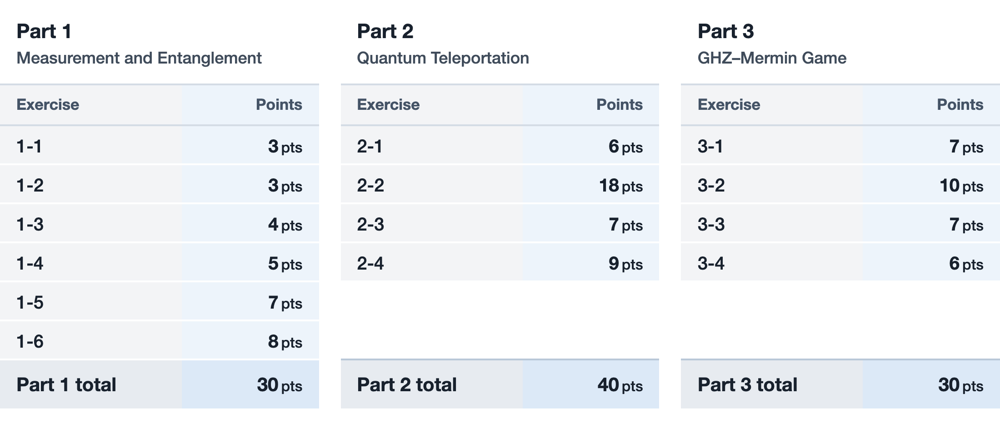

The core exercises are worth **100 points**. Optional exercise 2-5 offers **12 additional points**, and optional exercise 3-5 offers **8 additional points**, reported separately.

## Grading and Submission Instructions

Do not modify the final cell below. It collects the return values of your answer functions, grades them, and generates a submission ZIP. Check your core and additional scores and any incomplete items or errors. Unanswered optional exercises do not affect your core score.

- **Colab:** The final cell requests an automatic download of the submission ZIP. If the download does not start, check the displayed save path and download the ZIP from the file panel on the left.
- **Jupyter:** Click the **Download submission ZIP** link in the output of the final cell after running it again.
- **VS Code:** The ZIP is saved locally at the path shown next to **Submission ZIP:** in the final cell's output.

**Submit both the submission ZIP and the completed `.ipynb` notebook to the destination specified by the event organizers.** The notebook is not included in the ZIP. In Colab, save it using **File → Download → Download .ipynb**; in VS Code or Jupyter, save the notebook file containing your work. **Follow the event announcement for the submission destination, deadline, submission unit (individual or team), file naming rules, and contact channel.**

After editing your answers, save the notebook and run all cells. The results will be saved under a new run ID. Check that the run ID in the final grading result matches the submission ZIP. Files from previous runs are not overwritten. Running the grading cell and generating files does not by itself submit your work.

In Colab, download both the ZIP and your completed notebook before the session ends. Failure messages from the provided faulty circuits in 2-1 and 2-5 are intentional experiment results. Use the final grading result to check the status of your submitted answers.


In [ ]:
#@title Final Automatic Grading and Submission File Export — Do Not Modify
# Collect only the functions defined in the current execution. Omit unattempted optional exercises automatically.
# Grade the same collected snapshot and save it in the submission JSON, score report, and ZIP.
_qff_final_result = finalize_submission(globals(), language="en")


**References**

- [IBM: Quantum teleportation](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/quantum-teleportation)
- [Qiskit bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering) · [Conditional operations](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow)
- [Quantum Pseudo-Telepathy](https://arxiv.org/abs/quant-ph/0407221)
- [Classical bounds and quantum strategies for the GHZ game](https://arxiv.org/abs/quant-ph/0408090)
